# Transfer Learning em Detecção de Objetos

Projeto final de Visão Computacional. O estudo compara três estratégias de treinamento do mesmo detector e mede o ganho real da transferência de aprendizado:

- **A** — treino do zero, sem pesos pré-treinados.
- **B** — backbone pré-treinado congelado; só as camadas de detecção aprendem.
- **C** — fine-tuning completo a partir dos pesos pré-treinados.

Cada rodada registra precisão, recall e F1 em curvas individuais, mAP no protocolo COCO e matriz de confusão. O treinamento só começa quando `run_training` for `True`.

O detector, o conjunto de imagens e os limiares são parâmetros da rodada, definidos na seção 1.

## 1. Configuração

`CONFIG` reúne os parâmetros da rodada. A célula seguinte detecta o ambiente, resolve os caminhos e, no Colab, instala apenas os pacotes ausentes. Depois vêm as importações, a semente e o dispositivo.

Localmente, instale as bibliotecas antes de abrir o notebook: `uv sync --extra cpu` para CPU ou `uv run python scripts/setup_gpu.py` para GPU — o script identifica o sistema operacional e escolhe os pacotes certos. Abra o Jupyter pelo mesmo ambiente.

In [1]:
# Parâmetros da rodada. Ajuste aqui e reexecute esta célula antes de treinar.
# batch_size e num_workers só valem depois de recriar os DataLoaders (seção 4).
CONFIG = {
    'seed': 42,
    'dataset_dir': 'DeepPCB/PCBData',  # relativo a data/ no projeto ou dataset/ no Drive
    'experiment': 'C',                 # A: sem pesos | B: backbone congelado | C: fine-tuning completo
    'epochs': 20,
    'patience': 5,
    'batch_size': 2,
    'num_workers': 0,
    'amp': True,                       # precisão mista na GPU: ~2x mais rápido, mesmas imagens e modelo
    'learning_rate': 0.001,
    'momentum': 0.9,
    'weight_decay': 0.0005,
    'lr_step_size': 7,
    'lr_gamma': 0.1,
    'score_threshold': 0.5,
    'iou_threshold': 0.5,
    'run_training': True,
    'evaluate_test': False,
    'checkpoint_path': None,
}

In [2]:
# Ambiente e caminhos: o conjunto de imagens não é copiado para o runtime do Colab.
import importlib.util
import subprocess
import sys
from pathlib import Path

try:
    IN_COLAB = importlib.util.find_spec('google.colab') is not None
except (ImportError, ValueError):  # fora do Colab o pacote google nem existe
    IN_COLAB = False

if IN_COLAB:
    from google.colab import drive

    drive.mount('/content/drive')
    ROOT = Path('/content/drive/MyDrive/vision-transfer-learning')
    # O Colab já fornece PyTorch/TorchVision; preserve as versões instaladas.
    packages = {
        'numpy': 'numpy', 'pandas': 'pandas', 'matplotlib': 'matplotlib',
        'PIL': 'pillow', 'tqdm': 'tqdm', 'torch': 'torch',
        'torchvision': 'torchvision', 'torchmetrics': 'torchmetrics',
        'pycocotools': 'pycocotools',
    }
    missing = [package for module, package in packages.items() if importlib.util.find_spec(module) is None]
    if missing:
        subprocess.check_call([sys.executable, '-m', 'pip', 'install', *missing])
        importlib.invalidate_caches()
else:
    cwd = Path.cwd().resolve()
    ROOT = next((p for p in (cwd, *cwd.parents) if (p / 'pyproject.toml').is_file()), None)
    if ROOT is None:
        raise RuntimeError('Abra o notebook na pasta do projeto ou em uma subpasta.')
    if Path(sys.prefix).resolve() != (ROOT / '.venv').resolve():
        print('Use o kernel do ambiente uv do projeto: uv run --extra cpu jupyter lab (ou --extra cu128).')

DATA = ROOT / ('dataset' if IN_COLAB else 'data') / CONFIG['dataset_dir']
RESULTS = ROOT / 'runs' / 'results'
print('Ambiente:', 'Google Colab' if IN_COLAB else 'local')
print('Dados:', DATA)
print('Resultados:', RESULTS)

Ambiente: local
Dados: /home/miguelherdian/Faculdade_Visao_Computacional/vision-transfer-learning/data/DeepPCB/PCBData
Resultados: /home/miguelherdian/Faculdade_Visao_Computacional/vision-transfer-learning/runs/results


In [3]:
from pathlib import Path, PurePosixPath
from itertools import combinations
from datetime import datetime
import hashlib
import json
import random

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from matplotlib.ticker import MaxNLocator
from PIL import Image
from IPython.display import display
from tqdm.auto import tqdm

import torch
from torch.utils.data import Dataset, DataLoader
from torchvision.transforms.functional import pil_to_tensor
from torchvision.ops import box_iou
from torchvision.models.detection import fasterrcnn_resnet50_fpn_v2, FasterRCNN_ResNet50_FPN_V2_Weights
from torchvision.models.detection.faster_rcnn import FastRCNNPredictor
from torchmetrics.detection.mean_ap import MeanAveragePrecision

random.seed(CONFIG['seed'])
np.random.seed(CONFIG['seed'])
torch.manual_seed(CONFIG['seed'])
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(CONFIG['seed'])

DEVICE = torch.device(
    'cuda' if torch.cuda.is_available()
    else 'mps' if torch.backends.mps.is_available()
    else 'cpu'
)
print('Dispositivo:', DEVICE)

/home/miguelherdian/Faculdade_Visao_Computacional/vision-transfer-learning/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Dispositivo: cuda


## 2. Dados

Disponibilize as imagens anotadas em `data/<dataset_dir>` no projeto local ou em `MyDrive/vision-transfer-learning/dataset/<dataset_dir>` no Colab. A pasta deve conter `trainval.txt`, `test.txt` e os grupos referenciados; o notebook não baixa nem duplica arquivos.

Os splits listam o nome base da imagem: os arquivos reais terminam em `_test.jpg` (imagem inspecionada) e `_temp.jpg` (referência). As anotações trazem uma caixa por linha, em coordenadas XYXY absolutas seguidas da classe.

In [4]:
CLASSES = {1: 'open', 2: 'short', 3: 'mousebite', 4: 'spur', 5: 'copper', 6: 'pin-hole'}
NUM_CLASSES = len(CLASSES) + 1  # classes de defeito mais o fundo

if not DATA.is_dir():
    raise FileNotFoundError(f'Diretório do conjunto de imagens não encontrado: {DATA}')


def read_split(name):
    """Lê um split oficial e devolve as imagens e as caixas anotadas."""
    images, boxes = [], []
    for line in (DATA / f'{name}.txt').read_text(encoding='utf-8').splitlines():
        image_ref, annotation_ref = (PurePosixPath(part) for part in line.split())
        base = DATA.joinpath(*image_ref.parts).with_suffix('')
        annotation = DATA.joinpath(*annotation_ref.parts)
        images.append({
            'image_id': image_ref.stem,
            'group_id': image_ref.parts[0],
            'image_path': Path(f'{base}_test.jpg'),
            'template_path': Path(f'{base}_temp.jpg'),
            'annotation_path': annotation,
            'split': name,
        })
        for row in annotation.read_text(encoding='utf-8').splitlines():
            x1, y1, x2, y2, label = (float(value) for value in row.split())
            boxes.append({
                'image_id': image_ref.stem, 'class_id': int(label), 'class_name': CLASSES[int(label)],
                'x1': x1, 'y1': y1, 'x2': x2, 'y2': y2,
            })
    return images, boxes


trainval_images, trainval_boxes = read_split('trainval')
test_images, test_boxes = read_split('test')
summary = pd.DataFrame(trainval_images + test_images)
ann = pd.DataFrame(trainval_boxes + test_boxes)

print('Imagens:', len(summary), '| anotações:', len(ann))
display(ann.class_name.value_counts().rename('defeitos').to_frame())

Imagens: 1500 | anotações: 10013


,defeitos
class_name,
mousebite,1965
open,1942
spur,1625
short,1506
pin-hole,1501
copper,1474


## 3. Divisão e visualização

A validação usa grupos exclusivos, com proporção próxima de 15% e cobertura de classes quando possível. O teste oficial compartilha grupos com o conjunto de desenvolvimento: seus resultados não demonstram generalização para grupos independentes.

In [5]:
def choose_validation_groups(frame, annotations, seed):
    """Escolhe os grupos de validação que melhor cobrem as classes perto de 15% das imagens."""
    groups = sorted(frame.group_id.unique())
    candidates = []
    for size in range(1, len(groups)):
        for chosen in combinations(groups, size):
            mask = frame.group_id.isin(chosen)
            left = set(annotations[annotations.image_id.isin(frame.loc[~mask, 'image_id'])].class_id)
            right = set(annotations[annotations.image_id.isin(frame.loc[mask, 'image_id'])].class_id)
            missing = len(set(CLASSES) - left) + len(set(CLASSES) - right)
            balance = abs(int(mask.sum()) - 0.15 * len(frame))
            tie = hashlib.sha256(f'{seed}|{",".join(chosen)}'.encode()).hexdigest()
            candidates.append((missing, balance, tie, chosen))
    return min(candidates)[-1]


trainval = summary[summary.split == 'trainval']
test = summary[summary.split == 'test'].copy()
validation_groups = choose_validation_groups(trainval, ann, CONFIG['seed'])

val = trainval[trainval.group_id.isin(validation_groups)].assign(split='validation')
train = trainval[~trainval.group_id.isin(validation_groups)].assign(split='train')
split_df = pd.concat([train, val, test], ignore_index=True)

groups = {split: set(frame.group_id) for split, frame in split_df.groupby('split')}
shared = {f'{a}-{b}': sorted(groups[a] & groups[b])
          for a, b in [('train', 'validation'), ('train', 'test'), ('validation', 'test')]}
print('Contagens:', split_df.split.value_counts().to_dict())
print('Grupos compartilhados:', shared)
display(ann.merge(split_df[['image_id', 'split']], on='image_id')
           .groupby(['split', 'class_name']).size().unstack(fill_value=0))

Contagens: {'train': 850, 'test': 500, 'validation': 150}
Grupos compartilhados: {'train-validation': [], 'train-test': ['group00041', 'group13000', 'group20085', 'group44000', 'group92000'], 'validation-test': ['group50600', 'group77000']}


class_name,copper,mousebite,open,pin-hole,short,spur
split,,,,,,
test,464,586,659,470,478,483
train,888,1236,1143,873,912,1014
validation,122,143,140,158,116,128


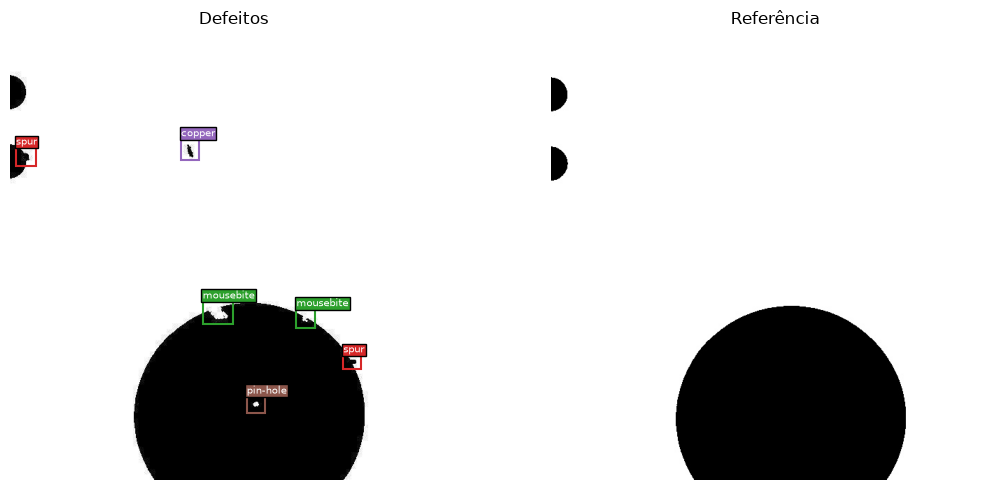

In [6]:
row = train.iloc[0]
boxes = ann[ann.image_id == row.image_id]
fig, axes = plt.subplots(1, 2, figsize=(11, 5))
with Image.open(row.image_path) as image:
    axes[0].imshow(image.convert('RGB'))
with Image.open(row.template_path) as image:
    axes[1].imshow(image.convert('RGB'))
for box in boxes.itertuples():
    color = plt.cm.tab10(box.class_id - 1)
    axes[0].add_patch(Rectangle((box.x1, box.y1), box.x2 - box.x1, box.y2 - box.y1,
                                fill=False, edgecolor=color, linewidth=1.5))
    axes[0].text(box.x1, max(0, box.y1 - 3), box.class_name, color='white',
                 fontsize=7, bbox={'facecolor': color, 'pad': 1})
axes[0].set_title('Defeitos')
axes[1].set_title('Referência')
for ax in axes:
    ax.axis('off')
plt.tight_layout()
plt.show()

## 4. Dataset e modelo

O modelo recebe apenas a imagem inspecionada, convertida para RGB em `[0, 1]`. O experimento A não carrega pesos COCO nem ImageNet; B congela o backbone e a FPN; C ajusta todos os parâmetros.

In [7]:
IMAGE_INDEX = {image_id: index for index, image_id in enumerate(sorted(summary.image_id.unique()))}


class DefectDetectionDataset(Dataset):
    def __init__(self, frame, annotations):
        self.frame = frame.reset_index(drop=True)
        self.annotations = dict(tuple(annotations.groupby('image_id')))
        self.empty = annotations.iloc[:0]

    def __len__(self):
        return len(self.frame)

    def __getitem__(self, index):
        row = self.frame.iloc[index]
        with Image.open(row.image_path) as image:
            tensor = pil_to_tensor(image.convert('RGB')).float() / 255.0
        annotations = self.annotations.get(row.image_id, self.empty)
        boxes = torch.as_tensor(
            annotations[['x1', 'y1', 'x2', 'y2']].to_numpy(dtype=np.float32, copy=True)
        ).reshape(-1, 4)
        target = {
            'boxes': boxes,
            'labels': torch.as_tensor(annotations.class_id.to_numpy(dtype=np.int64, copy=True)),
            'image_id': torch.tensor(IMAGE_INDEX[row.image_id], dtype=torch.int64),
            'area': (boxes[:, 2] - boxes[:, 0]) * (boxes[:, 3] - boxes[:, 1]),
            'iscrowd': torch.zeros(len(boxes), dtype=torch.int64),
        }
        return tensor, target


def collate_fn(batch):
    return tuple(zip(*batch))


def make_loader(split, shuffle=False):
    generator = torch.Generator().manual_seed(CONFIG['seed'])
    return DataLoader(datasets[split], batch_size=CONFIG['batch_size'], shuffle=shuffle,
                      num_workers=CONFIG['num_workers'], collate_fn=collate_fn, generator=generator)


datasets = {split: DefectDetectionDataset(split_df[split_df.split == split], ann)
            for split in ('train', 'validation', 'test')}
loaders = {split: make_loader(split, shuffle=split == 'train') for split in datasets}

In [8]:
WEIGHTS = FasterRCNN_ResNet50_FPN_V2_Weights.DEFAULT


def make_model(experiment):
    # weights_backbone=None impede que o experimento A baixe pesos ImageNet.
    model = fasterrcnn_resnet50_fpn_v2(weights=None if experiment == 'A' else WEIGHTS, weights_backbone=None)
    in_features = model.roi_heads.box_predictor.cls_score.in_features
    model.roi_heads.box_predictor = FastRCNNPredictor(in_features, NUM_CLASSES)
    for parameter in model.backbone.parameters():
        parameter.requires_grad = experiment != 'B'
    return model

## 5. Métricas e curvas

Precisão, recall e F1 são agregados sobre todos os defeitos (micro), com os limiares de confiança e IoU de `CONFIG`. Uma detecção correta precisa corresponder à mesma classe; predições e alvos sem par viram FP e FN. Cada métrica ganha a própria curva por época, salva como arquivo individual em `figures/` e reunida num painel para comparação.

A matriz de confusão usa associação espacial independente da classe, para expor trocas entre defeitos: linhas são classes reais e colunas são predições, incluindo fundo. O mAP segue o protocolo COCO; o benchmark DeepPCB original usa IoU 0,33 e não é diretamente comparável.

In [9]:
def match_detections(boxes, labels, scores, gt_boxes, gt_labels, iou_threshold, class_aware):
    """Casa cada predição com o alvo livre de maior IoU, da maior para a menor confiança."""
    ious = box_iou(boxes, gt_boxes) if len(boxes) and len(gt_boxes) else torch.zeros(len(boxes), len(gt_boxes))
    pairs, taken = [], set()
    for i in torch.argsort(scores, descending=True).tolist():
        candidates = [j for j in range(len(gt_boxes))
                      if j not in taken and ious[i, j] >= iou_threshold
                      and (not class_aware or labels[i] == gt_labels[j])]
        if not candidates:
            pairs.append((i, None))
            continue
        j = max(candidates, key=lambda index: float(ious[i, index]))
        taken.add(j)
        pairs.append((i, j))
    return pairs, taken


def detection_counts(prediction, target, score_threshold, iou_threshold):
    """Devolve (TP, FP, FN) com classe exigida e a matriz de confusão por posição."""
    keep = prediction['scores'] >= score_threshold
    boxes, labels, scores = (prediction[key][keep].cpu() for key in ('boxes', 'labels', 'scores'))
    gt_boxes, gt_labels = target['boxes'].cpu(), target['labels'].cpu()

    _, matched = match_detections(boxes, labels, scores, gt_boxes, gt_labels, iou_threshold, class_aware=True)
    counts = (len(matched), len(boxes) - len(matched), len(gt_boxes) - len(matched))

    confusion = np.zeros((NUM_CLASSES, NUM_CLASSES), dtype=np.int64)
    pairs, taken = match_detections(boxes, labels, scores, gt_boxes, gt_labels, iou_threshold, class_aware=False)
    for i, j in pairs:
        confusion[int(gt_labels[j]) if j is not None else 0, int(labels[i])] += 1
    for j in range(len(gt_boxes)):
        if j not in taken:
            confusion[int(gt_labels[j]), 0] += 1
    return counts, confusion


def evaluate(model, loader, device, config):
    use_amp = config.get('amp', False) and device.type == 'cuda'
    metric = MeanAveragePrecision(box_format='xyxy', iou_type='bbox', backend='pycocotools')
    confusion = np.zeros((NUM_CLASSES, NUM_CLASSES), dtype=np.int64)
    tp = fp = fn = 0
    model.eval()
    with torch.no_grad():
        for images, targets in tqdm(loader, desc='Avaliação', leave=False):
            with torch.autocast(device.type, enabled=use_amp):
                outputs = model([image.to(device) for image in images])
            # Converte para FP32: as métricas não devem depender da precisão do forward.
            predictions = [{k: (v.float() if v.is_floating_point() else v).detach().cpu()
                            for k, v in output.items()} for output in outputs]
            metric.update(predictions, [{k: target[k].cpu() for k in ('boxes', 'labels')} for target in targets])
            for prediction, target in zip(predictions, targets):
                (hits, extras, misses), matrix = detection_counts(
                    prediction, target, config['score_threshold'], config['iou_threshold'])
                tp += hits
                fp += extras
                fn += misses
                confusion += matrix

    coco = metric.compute()
    precision = tp / (tp + fp) if tp + fp else 0.0
    recall = tp / (tp + fn) if tp + fn else 0.0
    f1 = 2 * precision * recall / (precision + recall) if precision + recall else 0.0
    metrics = {
        'precision': precision, 'recall': recall, 'f1': f1,
        'map_50': float(coco['map_50']), 'map_50_95': float(coco['map']),
        'tp': tp, 'fp': fp, 'fn': fn,
    }
    return metrics, confusion

In [10]:
# Uma curva por métrica: precisão, recall e F1 são lidos separadamente.
CURVES = [
    ('precision', 'Precisão', (0, 1.02)),
    ('recall', 'Recall', (0, 1.02)),
    ('f1', 'F1-score', (0, 1.02)),
    ('map_50', 'mAP@0.50', (0, 1.02)),
    ('map_50_95', 'mAP@0.50:0.95', (0, 1.02)),
    ('train_loss', 'Perda de treino', None),
]


def draw_curve(ax, frame, key, title, limits):
    ax.plot(frame.epoch, frame[key], marker='o', linewidth=1.8)
    ax.set(xlabel='Época', ylabel=title, title=title)
    ax.xaxis.set_major_locator(MaxNLocator(integer=True))
    if limits is not None:
        ax.set_ylim(*limits)
    ax.grid(alpha=0.3)


def plot_history(history, run_dir):
    """Salva uma figura por métrica e um painel com todas elas."""
    frame = pd.DataFrame(history)
    figures = run_dir / 'figures'
    for key, title, limits in CURVES:
        fig, ax = plt.subplots(figsize=(5, 3.5))
        draw_curve(ax, frame, key, title, limits)
        fig.tight_layout()
        fig.savefig(figures / f'curve_{key}.png', dpi=150)
        plt.close(fig)

    fig, axes = plt.subplots(2, 3, figsize=(15, 8))
    for ax, curve in zip(axes.ravel(), CURVES):
        draw_curve(ax, frame, *curve)
    fig.suptitle('Validação por época')
    fig.tight_layout()
    fig.savefig(figures / 'training_curves.png', dpi=150)
    display(fig)
    plt.close(fig)


def plot_confusion(matrix, run_dir, tag):
    names = ['fundo', *CLASSES.values()]
    fig, ax = plt.subplots(figsize=(8, 7))
    image = ax.imshow(matrix, cmap='Blues')
    ax.set(xticks=range(NUM_CLASSES), yticks=range(NUM_CLASSES), xticklabels=names, yticklabels=names,
           xlabel='Predição', ylabel='Classe real', title=f'Matriz de confusão — {tag}')
    plt.setp(ax.get_xticklabels(), rotation=45, ha='right')
    threshold = matrix.max() / 2
    for i in range(NUM_CLASSES):
        for j in range(NUM_CLASSES):
            ax.text(j, i, str(matrix[i, j]), ha='center', va='center',
                    color='white' if matrix[i, j] > threshold else 'black')
    fig.colorbar(image, ax=ax)
    fig.tight_layout()
    fig.savefig(run_dir / 'figures' / f'confusion_{tag}.png', dpi=150)
    display(fig)
    plt.close(fig)

## 6. Treinamento e avaliação

Cada rodada cria um diretório exclusivo em `runs/results/` no projeto local ou em `MyDrive/vision-transfer-learning/runs/results/` no Colab, com configuração, divisão, histórico, figuras e melhor checkpoint. O melhor checkpoint é o de maior mAP@0.50:0.95 na validação, e o treino para após `patience` épocas sem ganho.

Para avaliar o teste oficial depois de escolher o experimento, defina `evaluate_test=True` e informe `checkpoint_path`, ou execute o teste ao fim do treinamento. Caminhos relativos de checkpoint partem da raiz do projeto no ambiente ativo.

In [11]:
def create_run(config):
    RESULTS.mkdir(parents=True, exist_ok=True)
    while True:
        run_dir = RESULTS / f'{datetime.now():%Y%m%d_%H%M%S_%f}_{config["experiment"]}'
        try:
            run_dir.mkdir()
            break
        except FileExistsError:
            continue
    (run_dir / 'figures').mkdir()
    (run_dir / 'checkpoints').mkdir()
    (run_dir / 'config.json').write_text(json.dumps(config, indent=2, ensure_ascii=False), encoding='utf-8')
    # Caminhos relativos tornam a divisão portátil entre instalações.
    split_df[['image_id', 'group_id', 'split']].to_csv(run_dir / 'split.csv', index=False)
    return run_dir


def train_one_epoch(model, loader, optimizer, scaler, device):
    model.train()
    if not any(parameter.requires_grad for parameter in model.backbone.parameters()):
        model.backbone.eval()
    total = 0.0
    for images, targets in tqdm(loader, desc='Treino', leave=False):
        images = [image.to(device) for image in images]
        targets = [{k: v.to(device) for k, v in target.items()} for target in targets]
        with torch.autocast(device.type, enabled=scaler.is_enabled()):
            loss = sum(model(images, targets).values())
        if not torch.isfinite(loss):
            raise RuntimeError('Perda não finita')
        optimizer.zero_grad()
        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()
        total += loss.item()
    return total / len(loader)


def train_experiment(config, run_dir):
    random.seed(config['seed'])
    np.random.seed(config['seed'])
    torch.manual_seed(config['seed'])
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(config['seed'])

    model = make_model(config['experiment']).to(DEVICE)
    optimizer = torch.optim.SGD(
        (parameter for parameter in model.parameters() if parameter.requires_grad),
        lr=config['learning_rate'], momentum=config['momentum'], weight_decay=config['weight_decay'])
    scheduler = torch.optim.lr_scheduler.StepLR(optimizer, step_size=config['lr_step_size'], gamma=config['lr_gamma'])
    scaler = torch.amp.GradScaler(DEVICE.type, enabled=config.get('amp', False) and DEVICE.type == 'cuda')

    train_loader = make_loader('train', shuffle=True)
    checkpoint = run_dir / 'checkpoints' / 'best.pt'
    history, best, stale = [], -1.0, 0

    for epoch in range(1, config['epochs'] + 1):
        loss = train_one_epoch(model, train_loader, optimizer, scaler, DEVICE)
        metrics, confusion = evaluate(model, loaders['validation'], DEVICE, config)
        scheduler.step()

        history.append({'epoch': epoch, 'train_loss': loss, **metrics})
        pd.DataFrame(history).to_csv(run_dir / 'history.csv', index=False)
        plot_history(history, run_dir)
        print(f'Época {epoch}: perda={loss:.4f} | precisão={metrics["precision"]:.3f} | '
              f'recall={metrics["recall"]:.3f} | F1={metrics["f1"]:.3f} | mAP={metrics["map_50_95"]:.3f}')

        if metrics['map_50_95'] > best:
            best, stale = metrics['map_50_95'], 0
            torch.save({'model': model.state_dict(), 'optimizer': optimizer.state_dict(),
                        'scheduler': scheduler.state_dict(), 'scaler': scaler.state_dict(), 'epoch': epoch,
                        'config': dict(config), 'best_map': best}, checkpoint)
            plot_confusion(confusion, run_dir, 'validation')
            np.save(run_dir / 'confusion_validation.npy', confusion)
        else:
            stale += 1
            if stale >= config['patience']:
                print('Early stopping')
                break
    return checkpoint


def evaluate_checkpoint(path, run_dir, config):
    path = Path(path)
    path = path if path.is_absolute() else ROOT / path
    # Carregue apenas checkpoints de origem confiável.
    saved = torch.load(path, map_location='cpu', weights_only=False)
    model = make_model(saved['config']['experiment']).to(DEVICE)
    model.load_state_dict(saved['model'])
    metrics, confusion = evaluate(model, loaders['test'], DEVICE, config)
    (run_dir / 'test_metrics.json').write_text(json.dumps(metrics, indent=2), encoding='utf-8')
    np.save(run_dir / 'confusion_test.npy', confusion)
    plot_confusion(confusion, run_dir, 'test')
    return metrics

Rodada: /home/miguelherdian/Faculdade_Visao_Computacional/vision-transfer-learning/runs/results/20261108_093008_344655_C


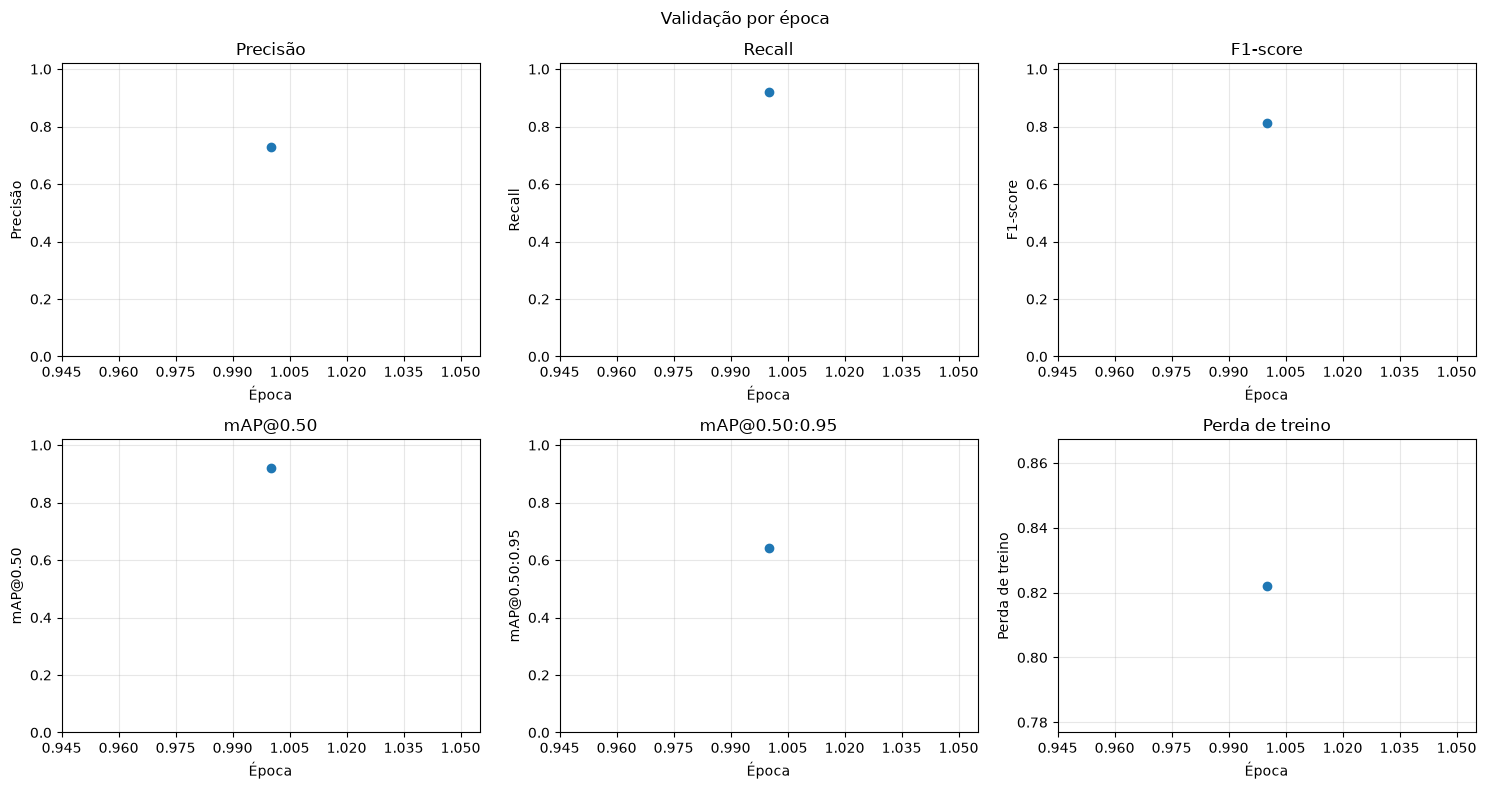

Época 1: perda=0.8221 | precisão=0.729 | recall=0.922 | F1=0.814 | mAP=0.642


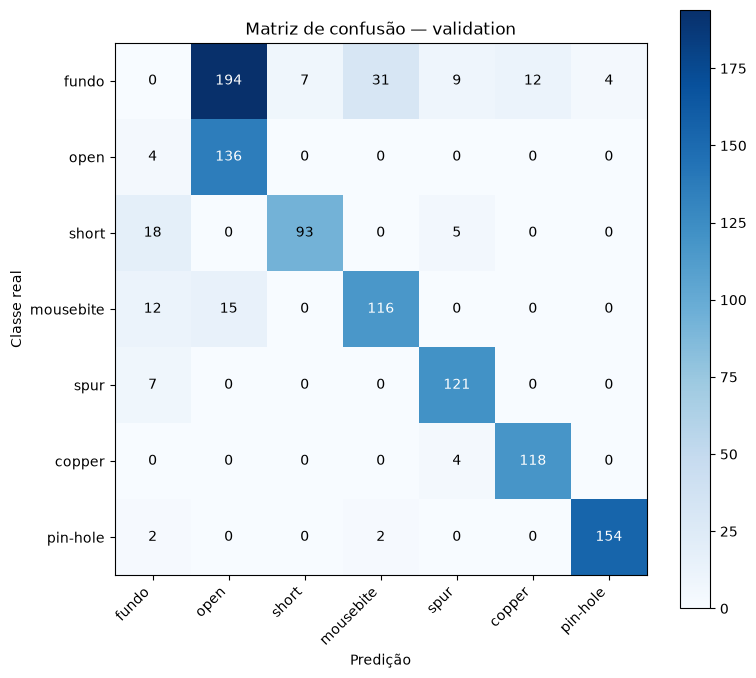

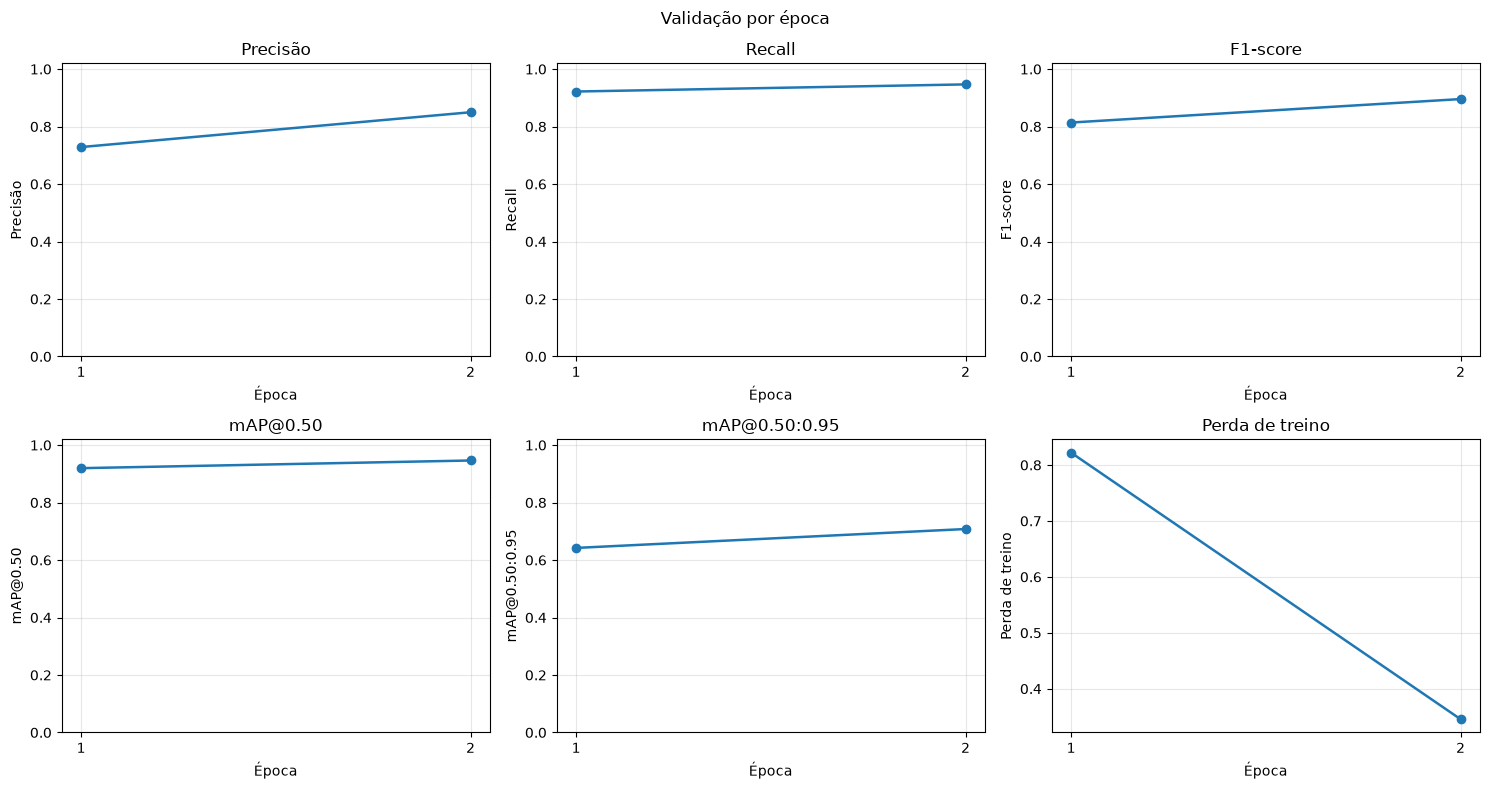

Época 2: perda=0.3456 | precisão=0.850 | recall=0.947 | F1=0.896 | mAP=0.708


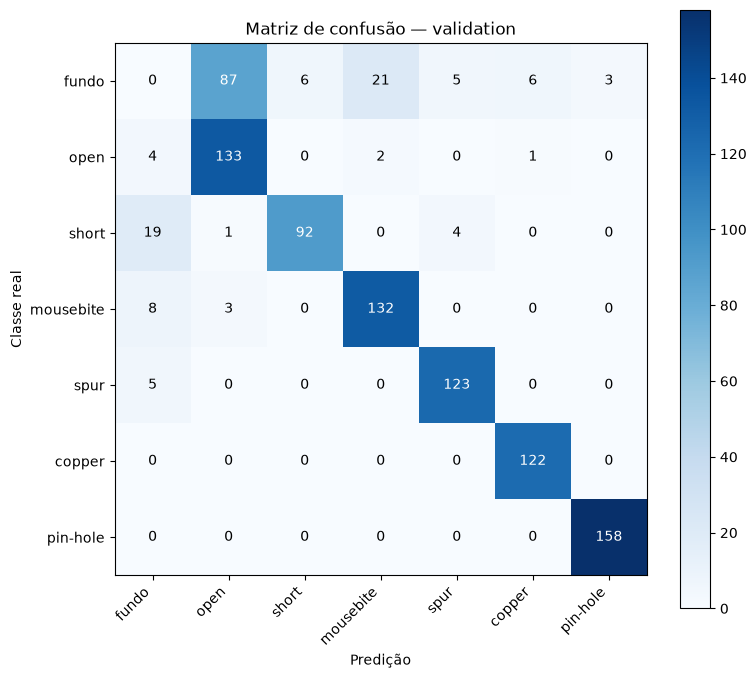

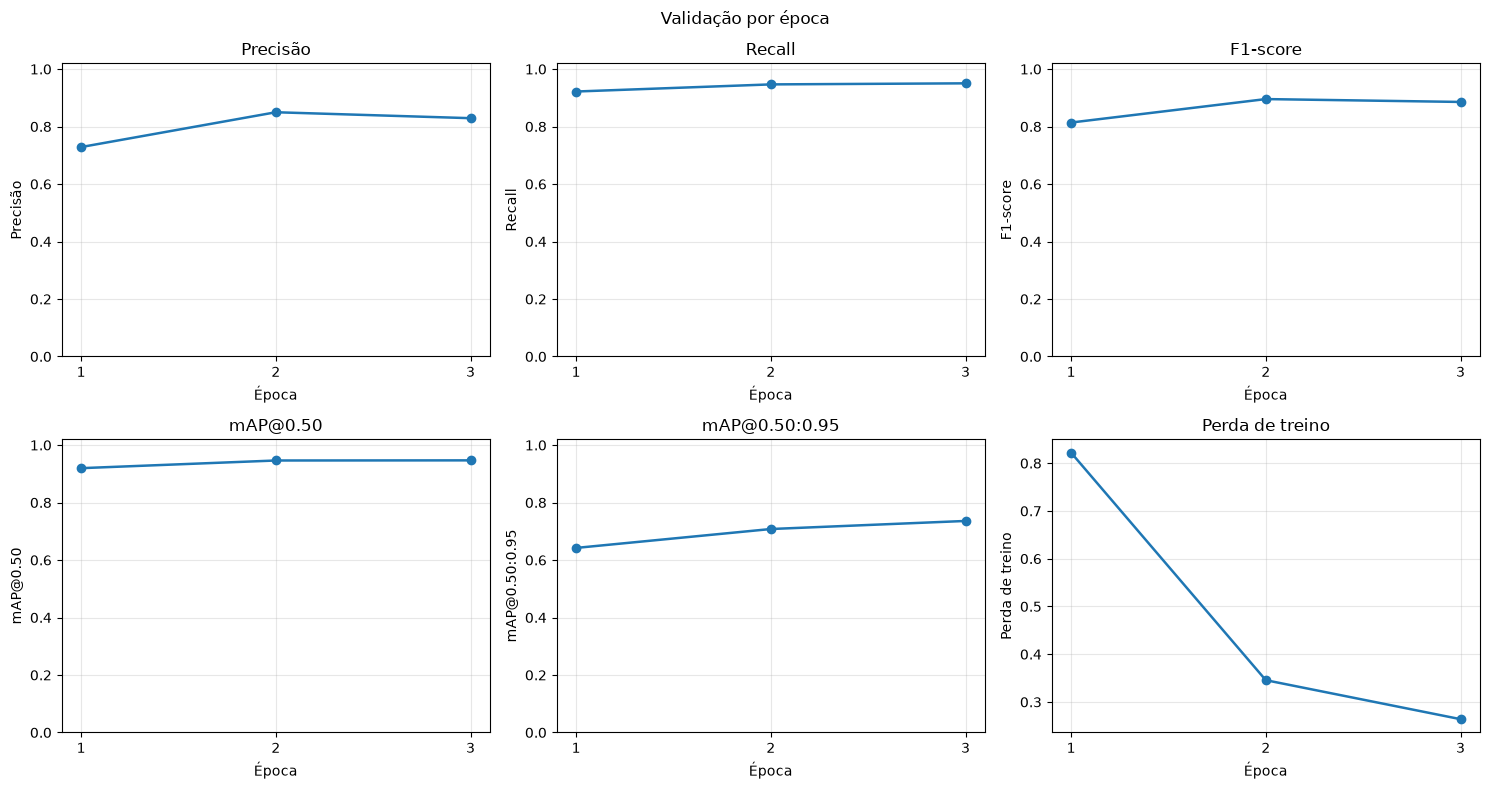

Época 3: perda=0.2640 | precisão=0.829 | recall=0.950 | F1=0.886 | mAP=0.736


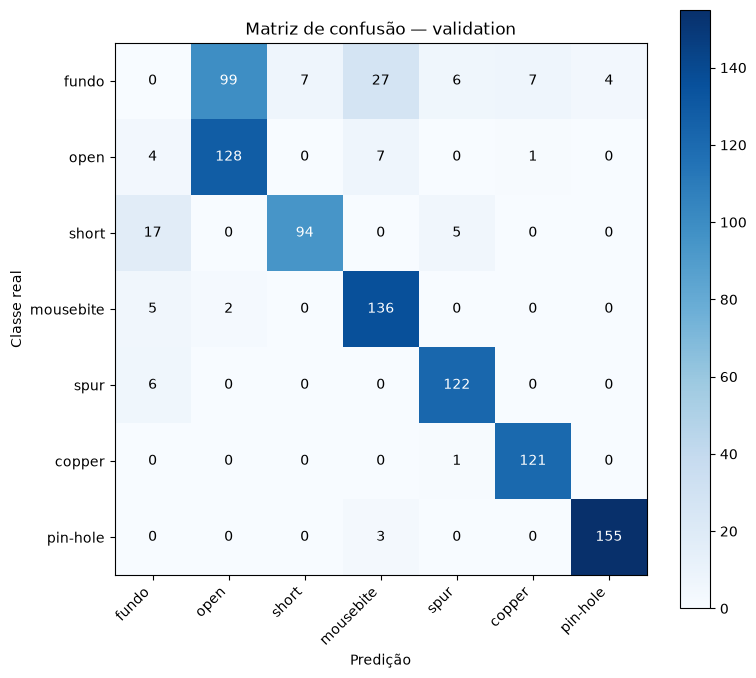

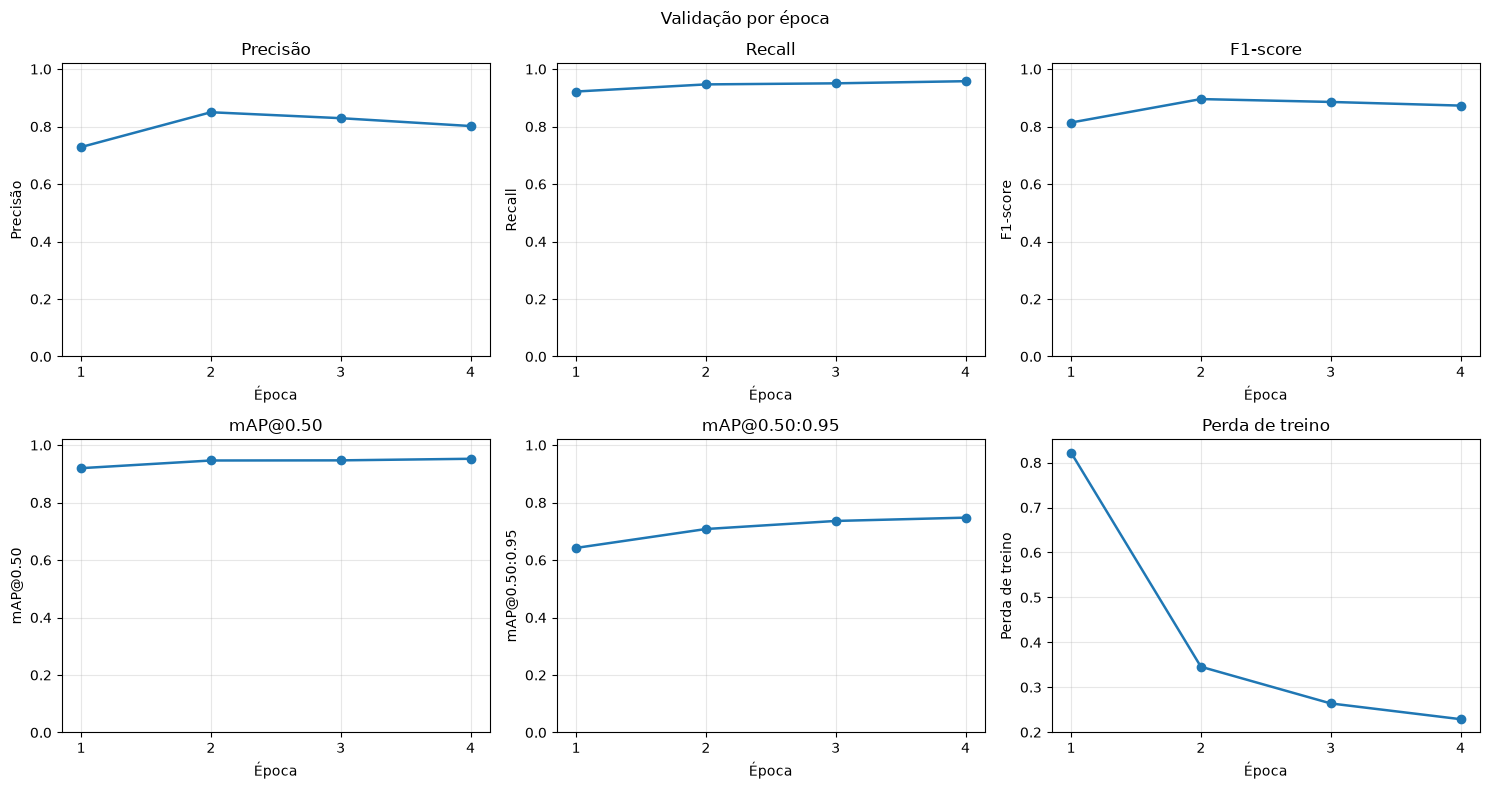

Época 4: perda=0.2290 | precisão=0.802 | recall=0.958 | F1=0.873 | mAP=0.748


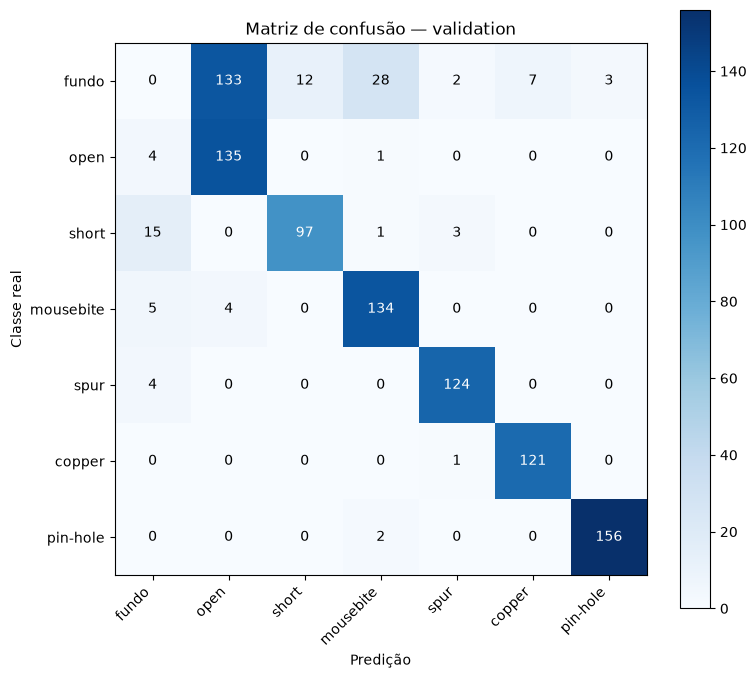

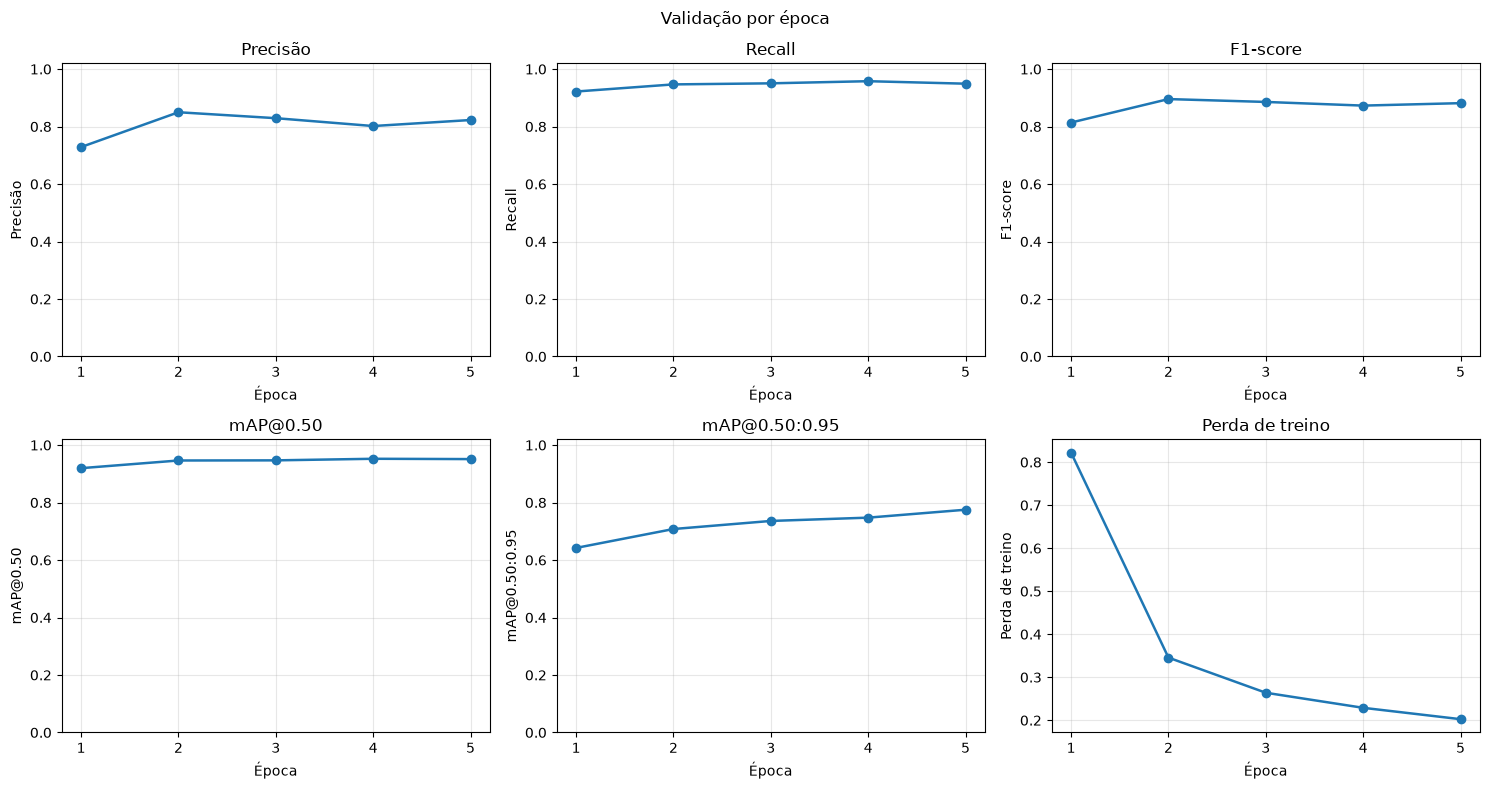

Época 5: perda=0.2026 | precisão=0.823 | recall=0.949 | F1=0.881 | mAP=0.775


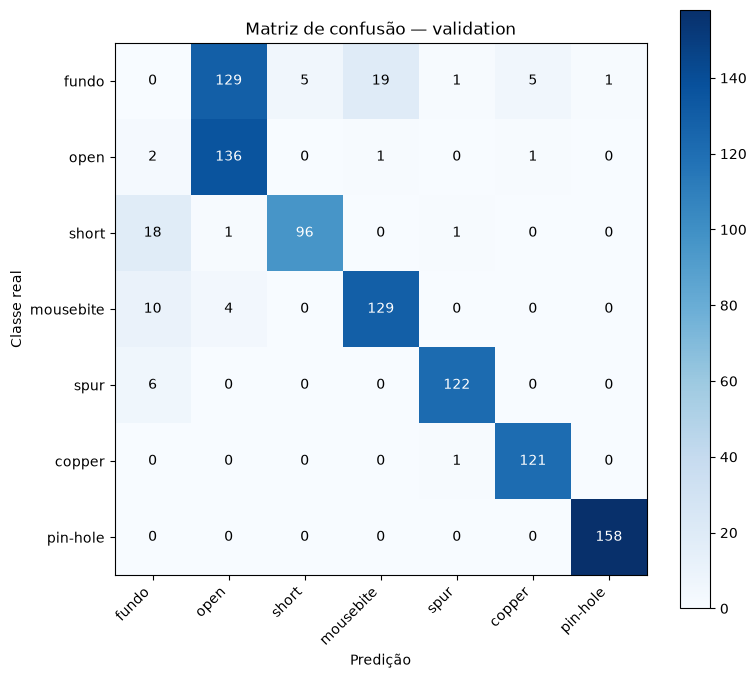

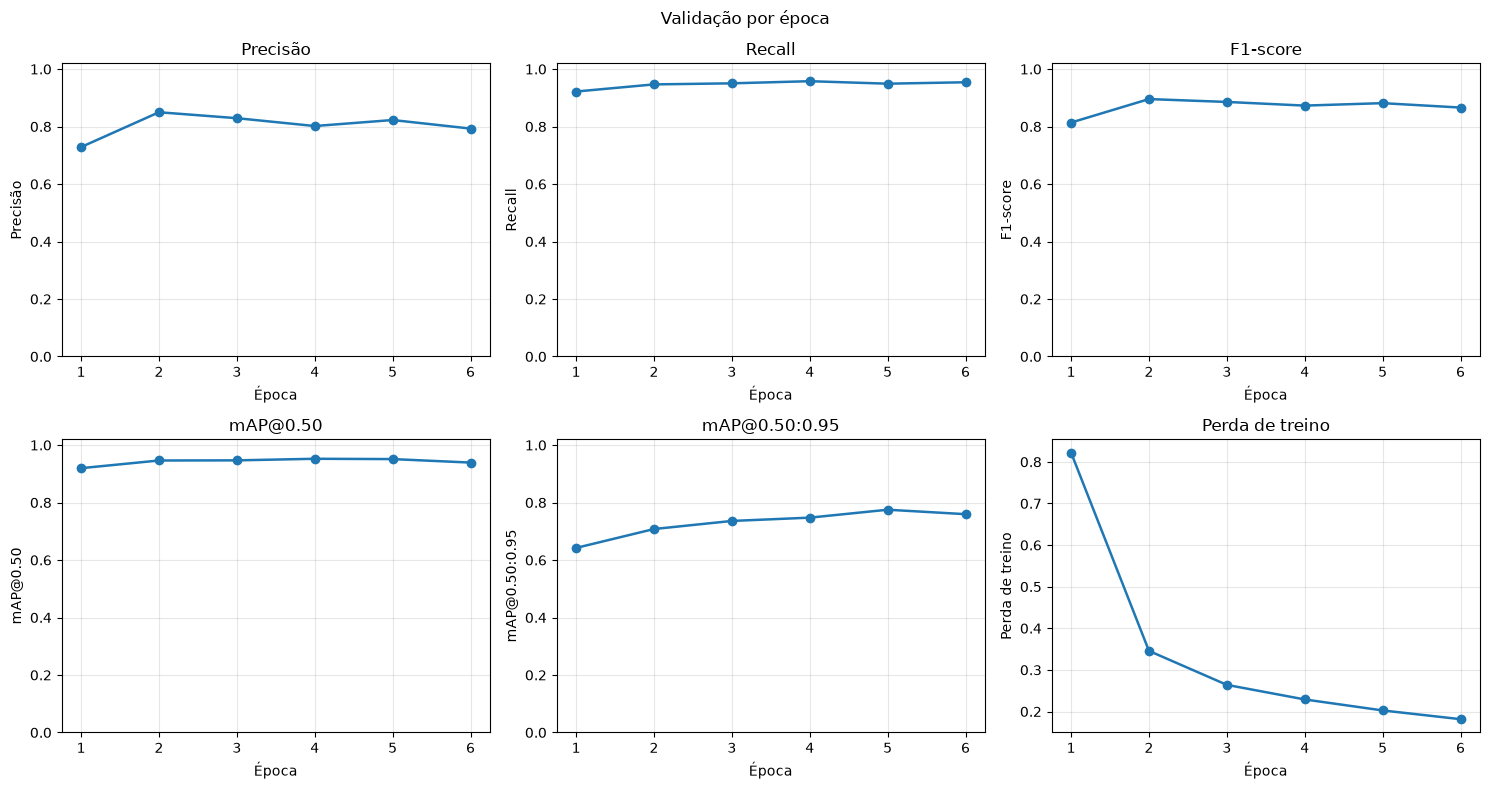

Época 6: perda=0.1816 | precisão=0.793 | recall=0.954 | F1=0.866 | mAP=0.760


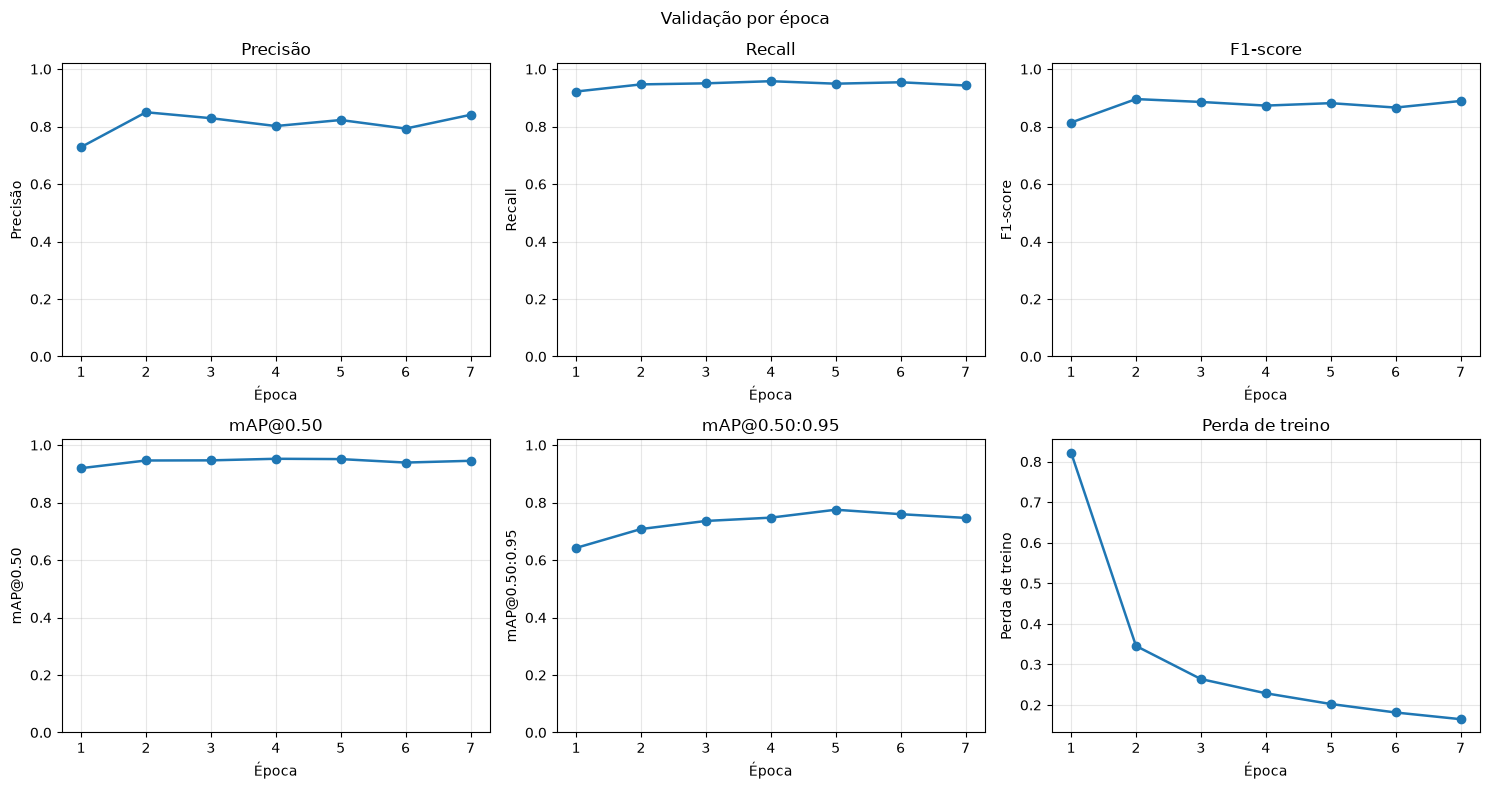

Época 7: perda=0.1651 | precisão=0.841 | recall=0.943 | F1=0.889 | mAP=0.747


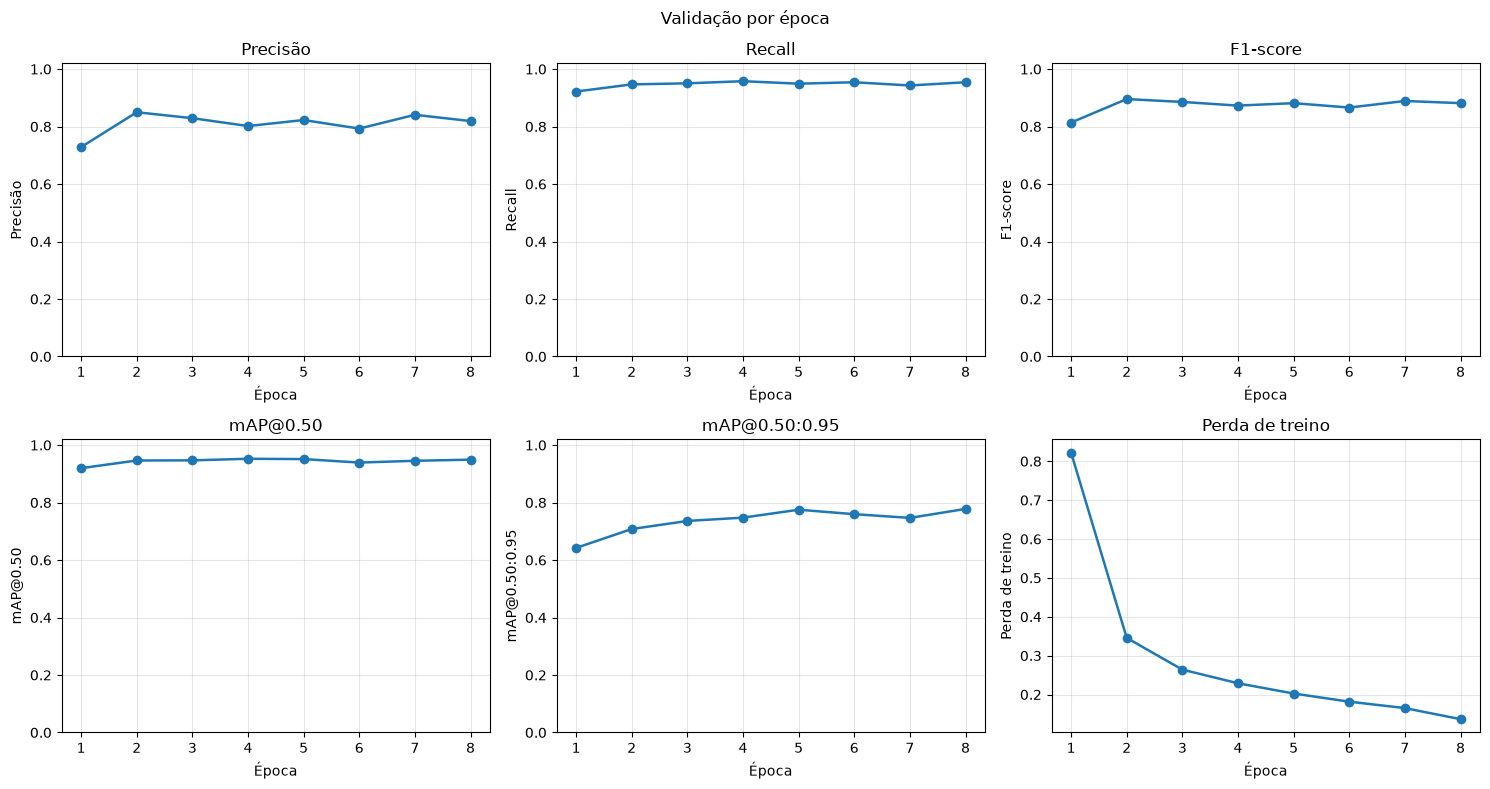

Época 8: perda=0.1366 | precisão=0.819 | recall=0.954 | F1=0.882 | mAP=0.778


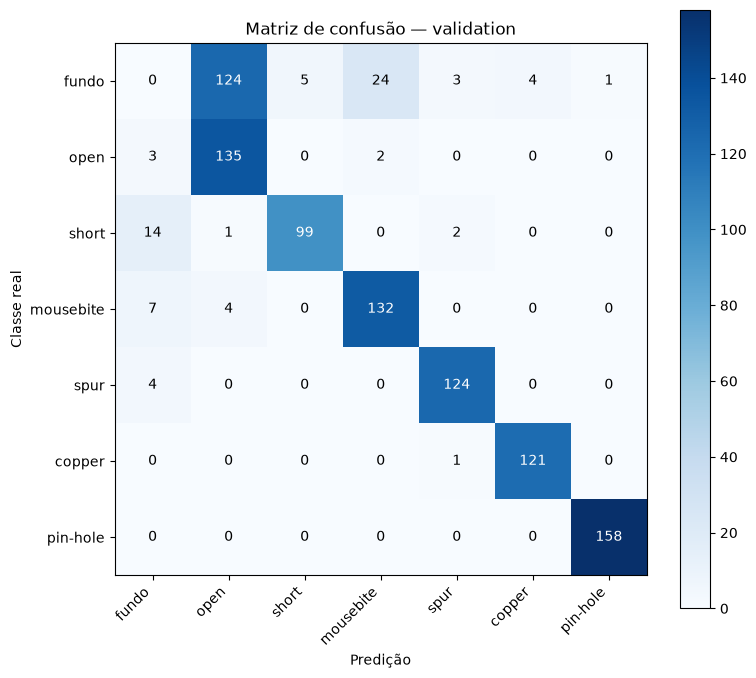

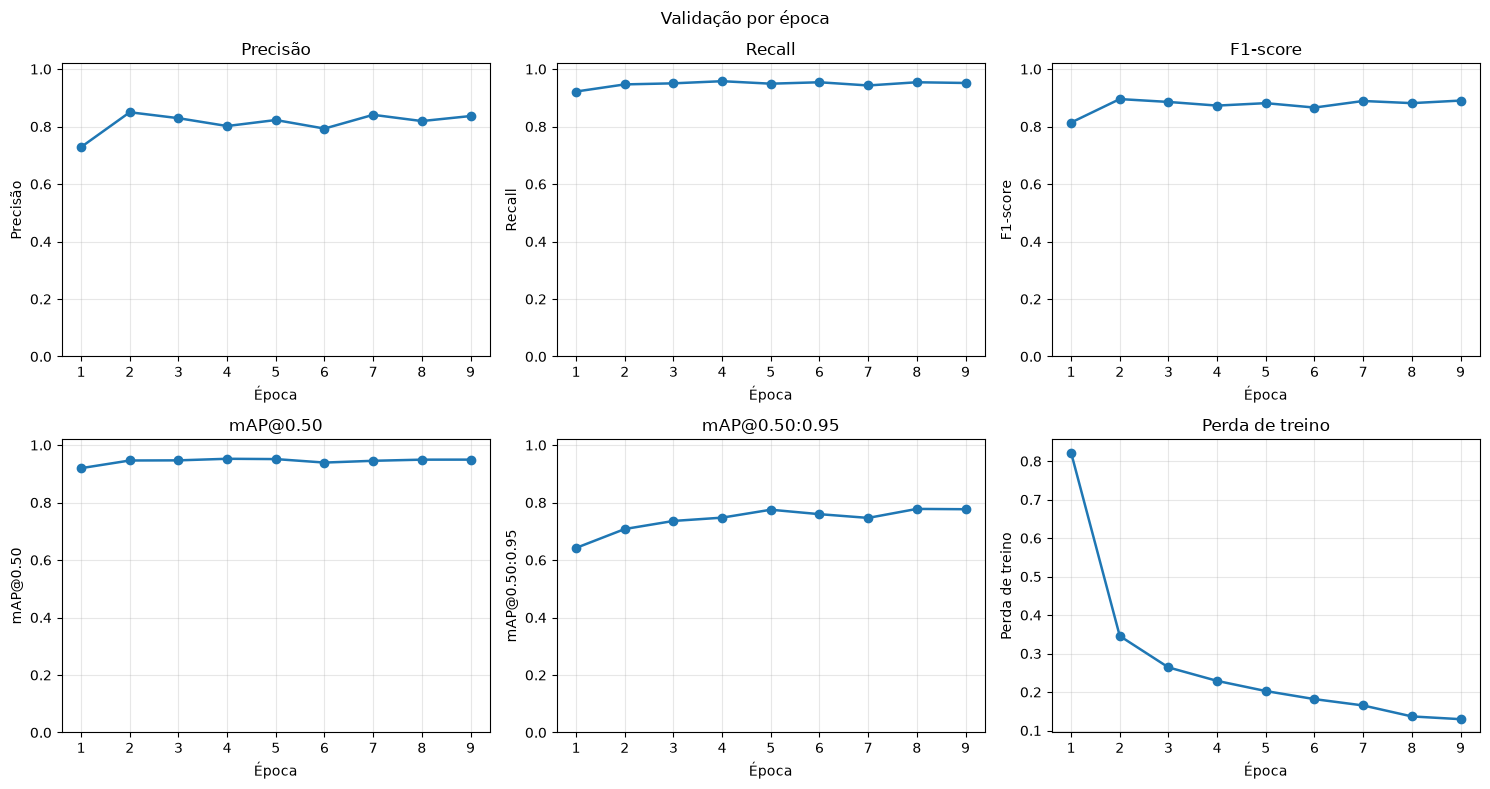

Época 9: perda=0.1295 | precisão=0.837 | recall=0.952 | F1=0.890 | mAP=0.777


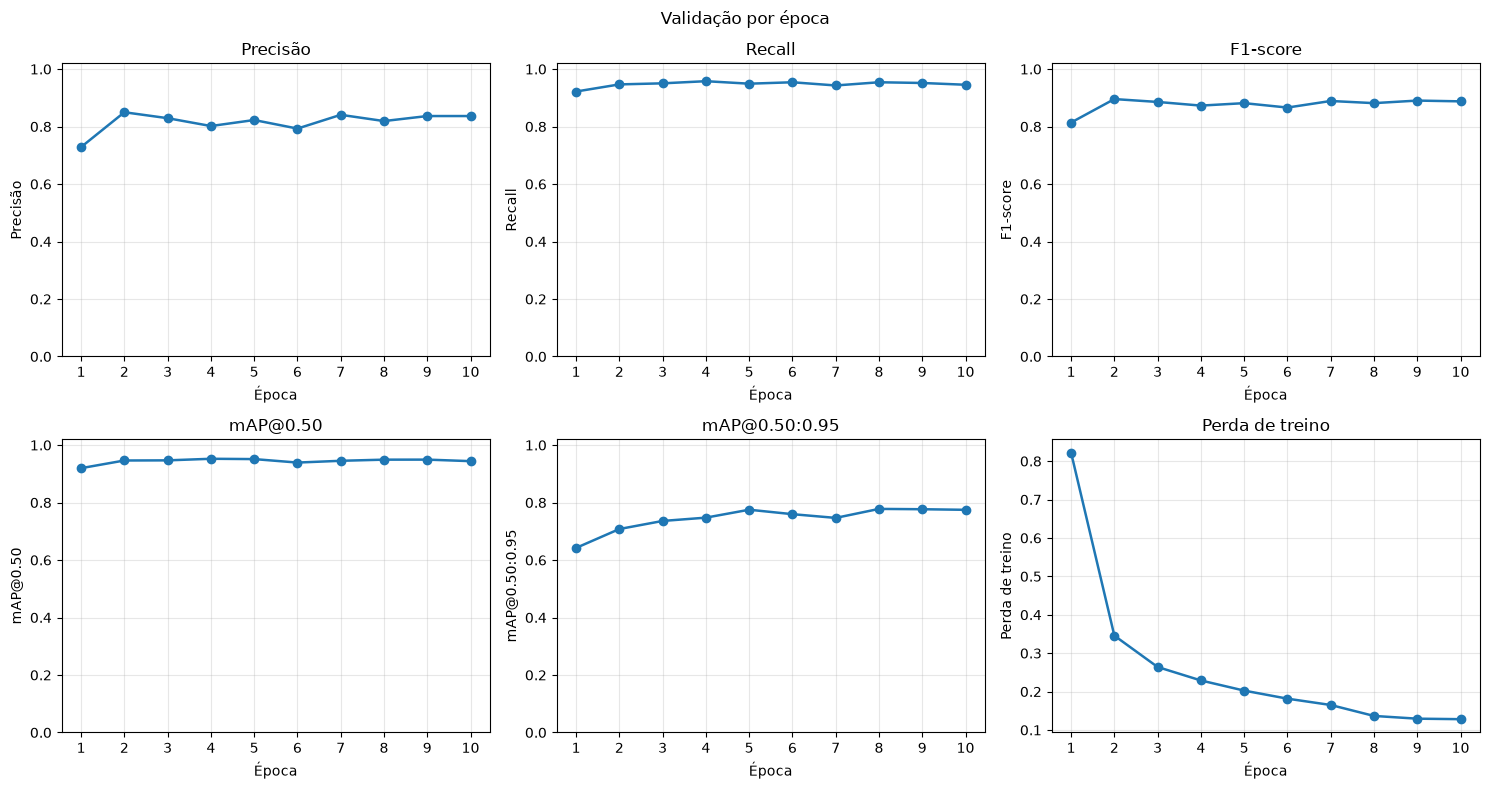

Época 10: perda=0.1282 | precisão=0.837 | recall=0.945 | F1=0.888 | mAP=0.775


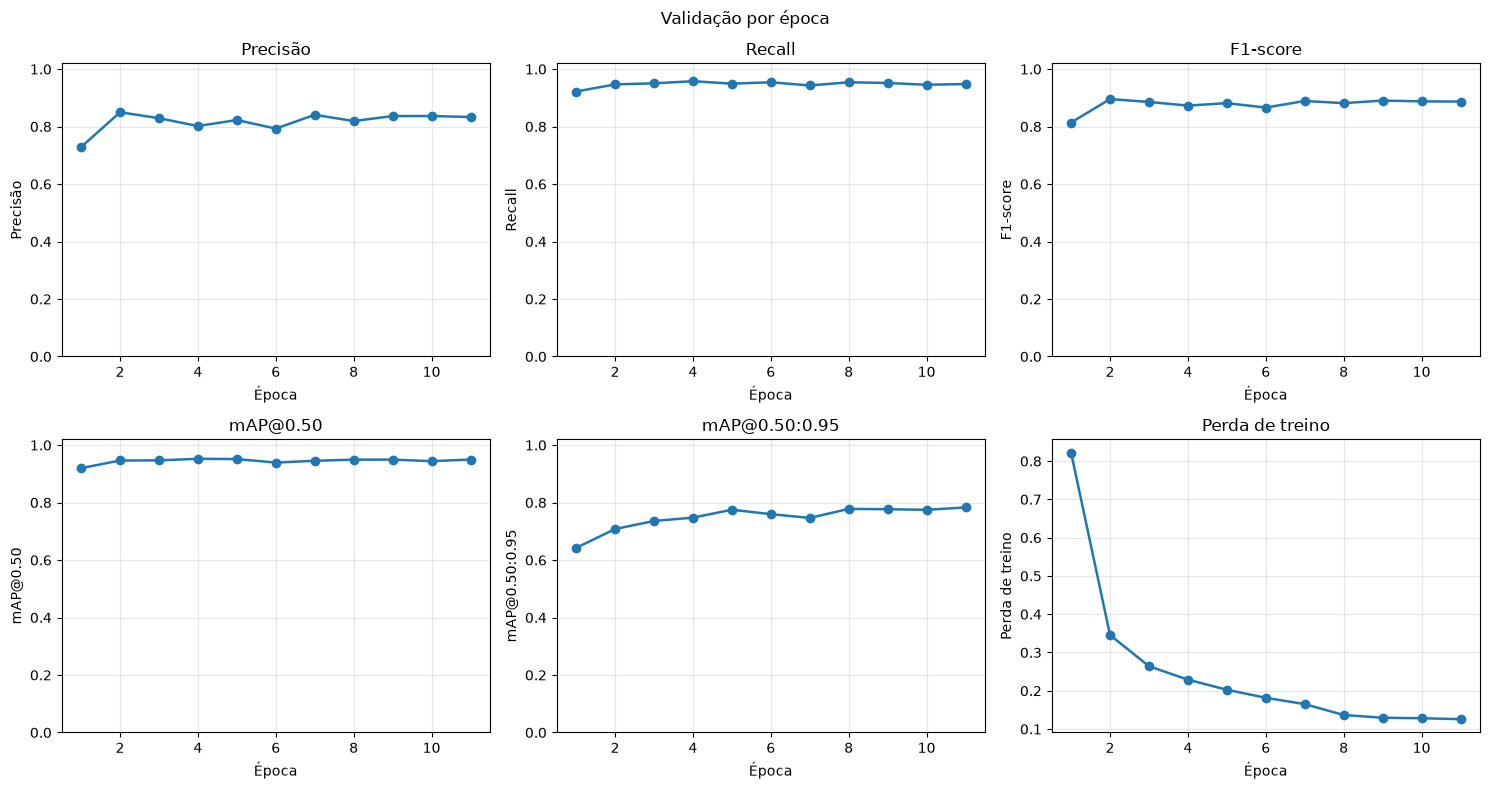

Época 11: perda=0.1257 | precisão=0.833 | recall=0.948 | F1=0.887 | mAP=0.783


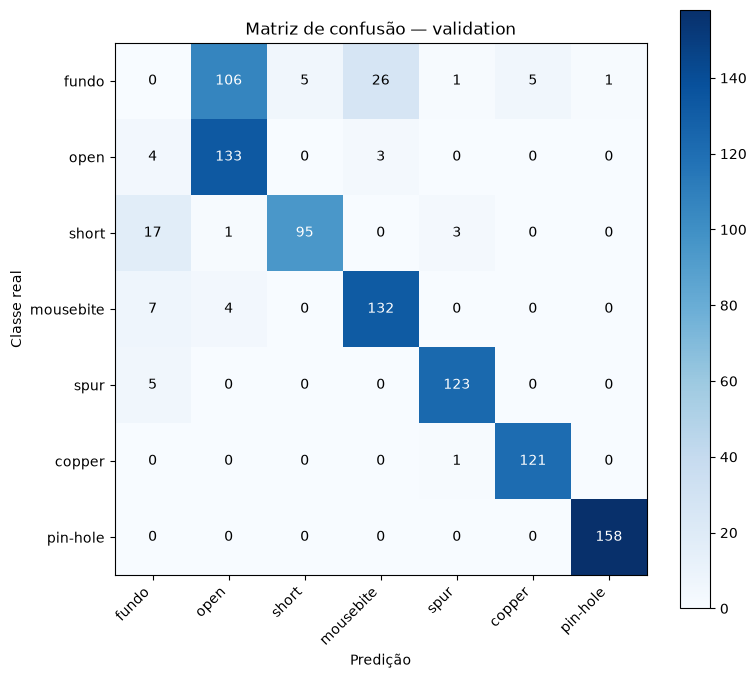

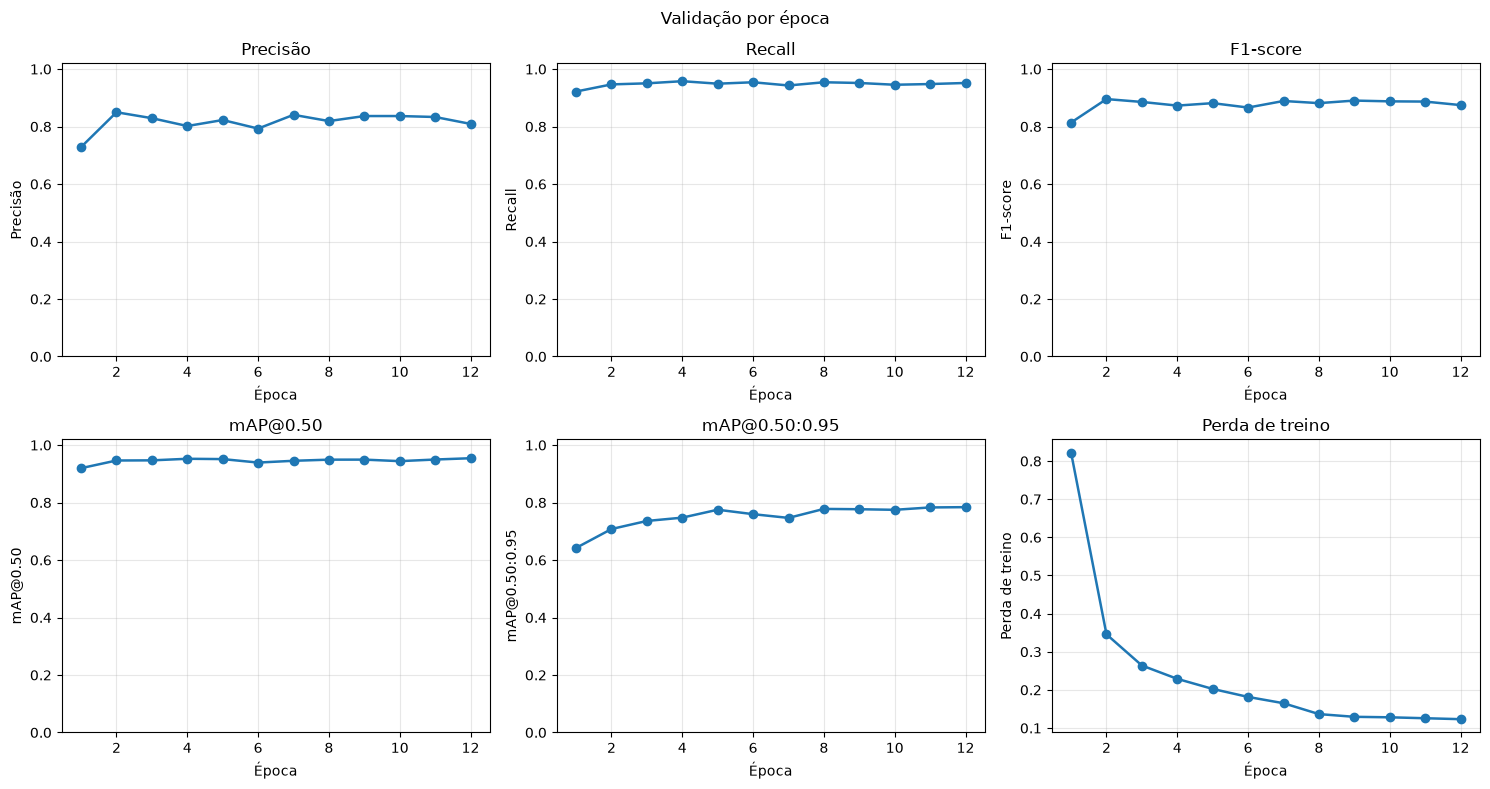

Época 12: perda=0.1233 | precisão=0.809 | recall=0.952 | F1=0.875 | mAP=0.784


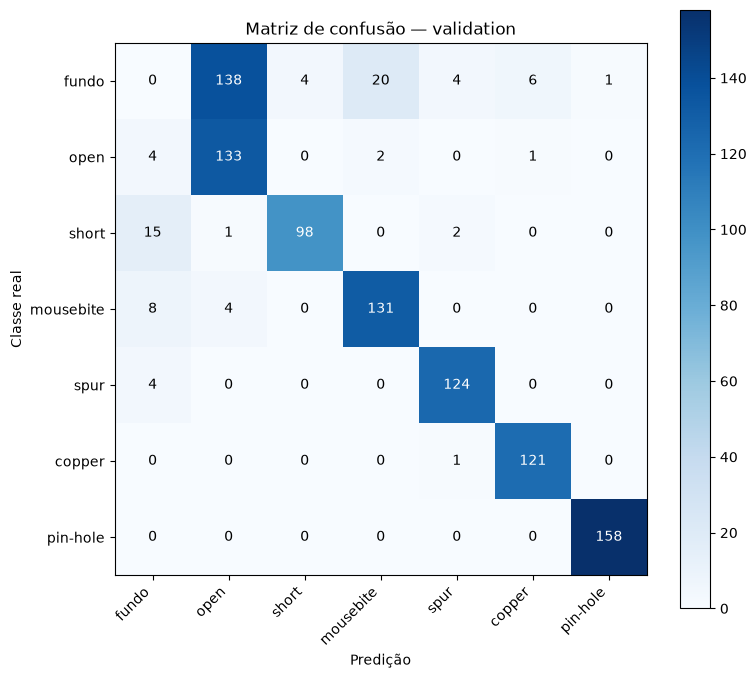

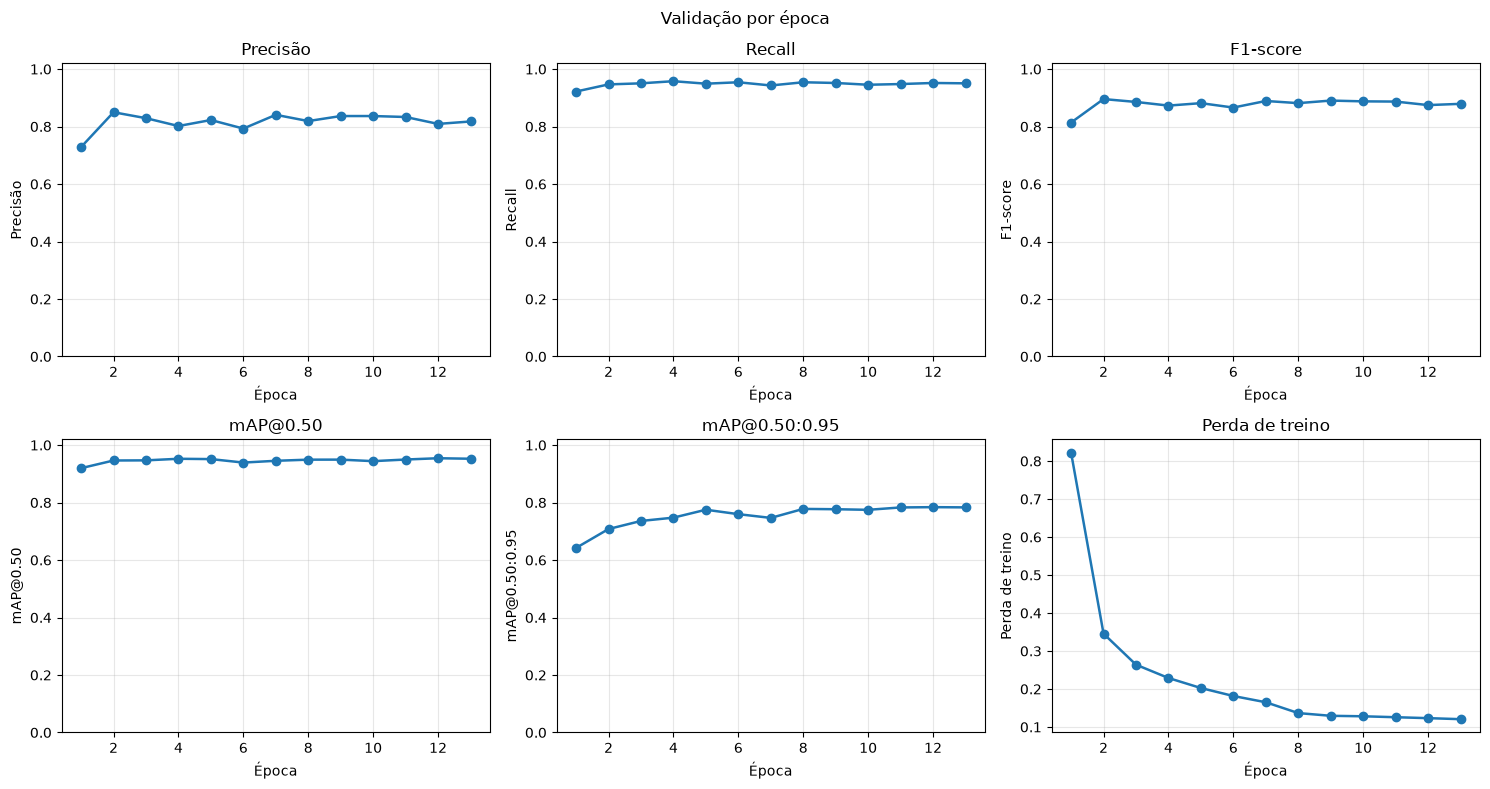

Época 13: perda=0.1206 | precisão=0.818 | recall=0.950 | F1=0.879 | mAP=0.783


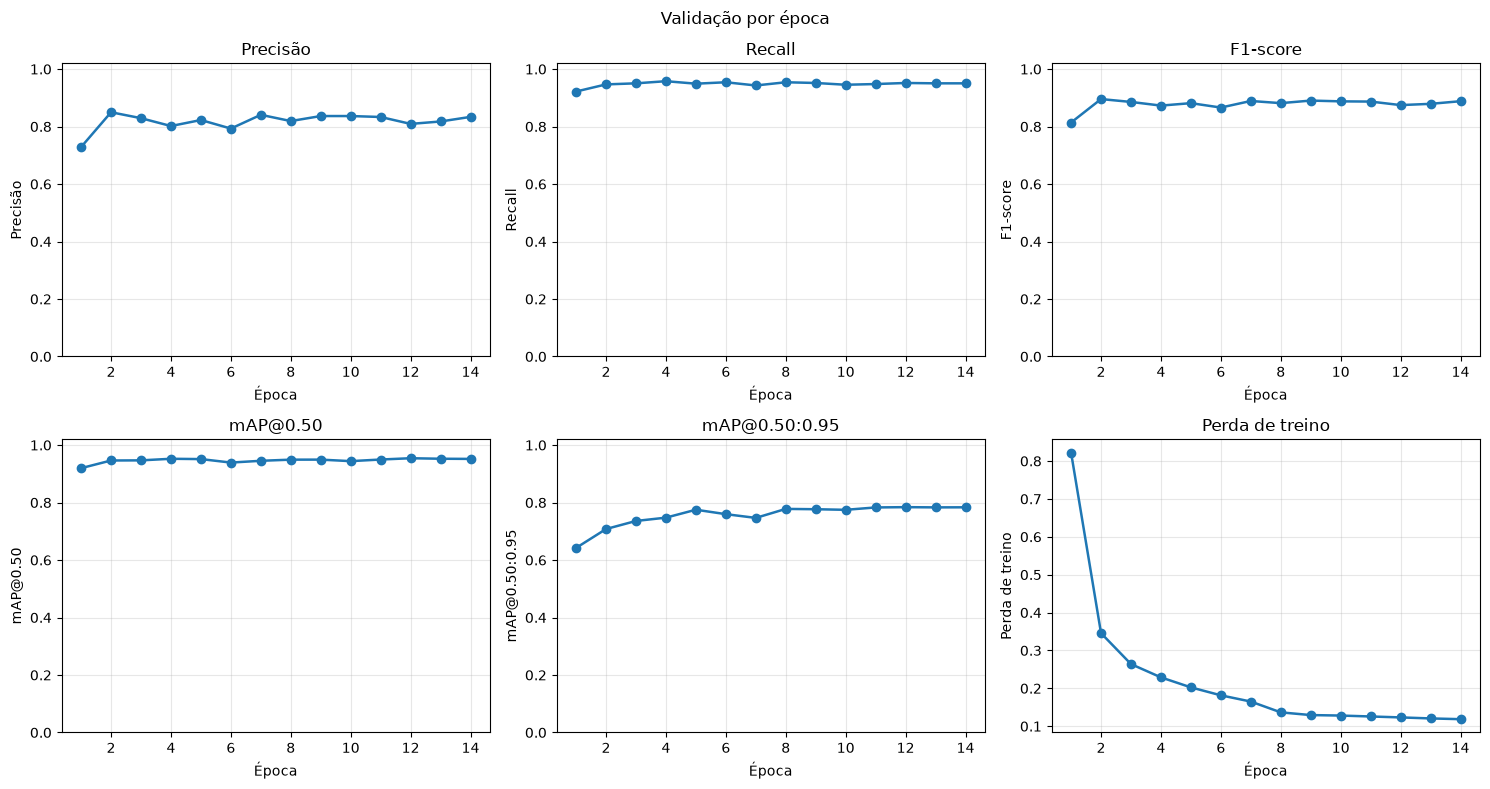

Época 14: perda=0.1186 | precisão=0.834 | recall=0.950 | F1=0.888 | mAP=0.784


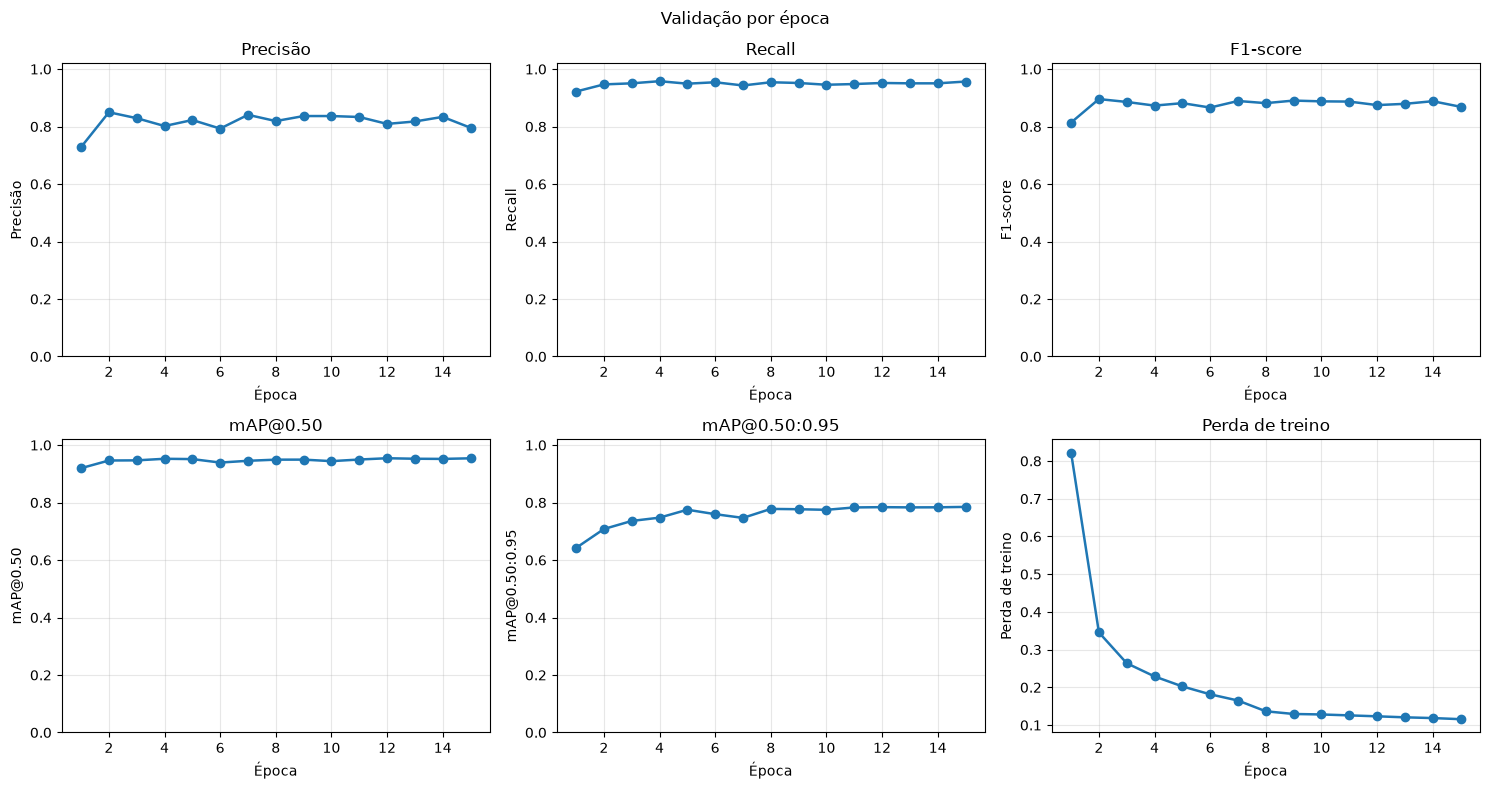

Época 15: perda=0.1157 | precisão=0.796 | recall=0.957 | F1=0.869 | mAP=0.785


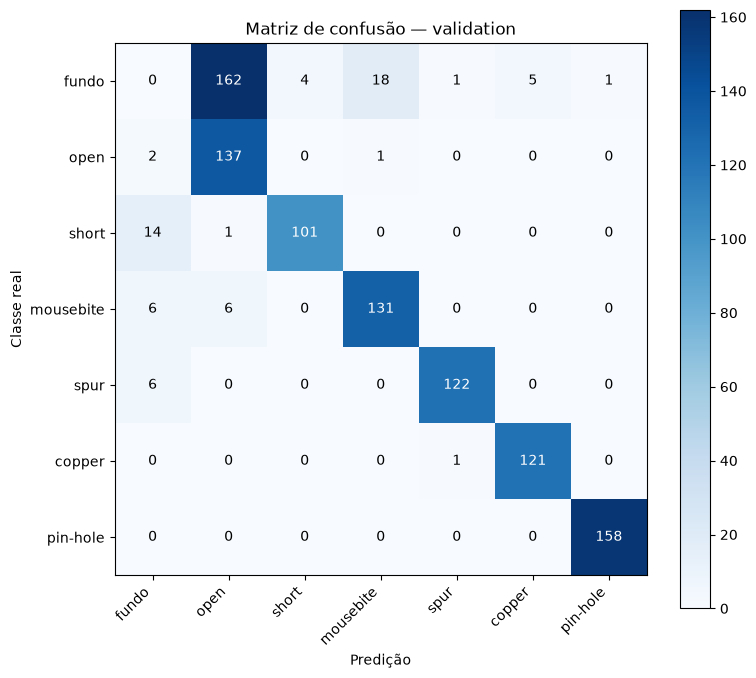

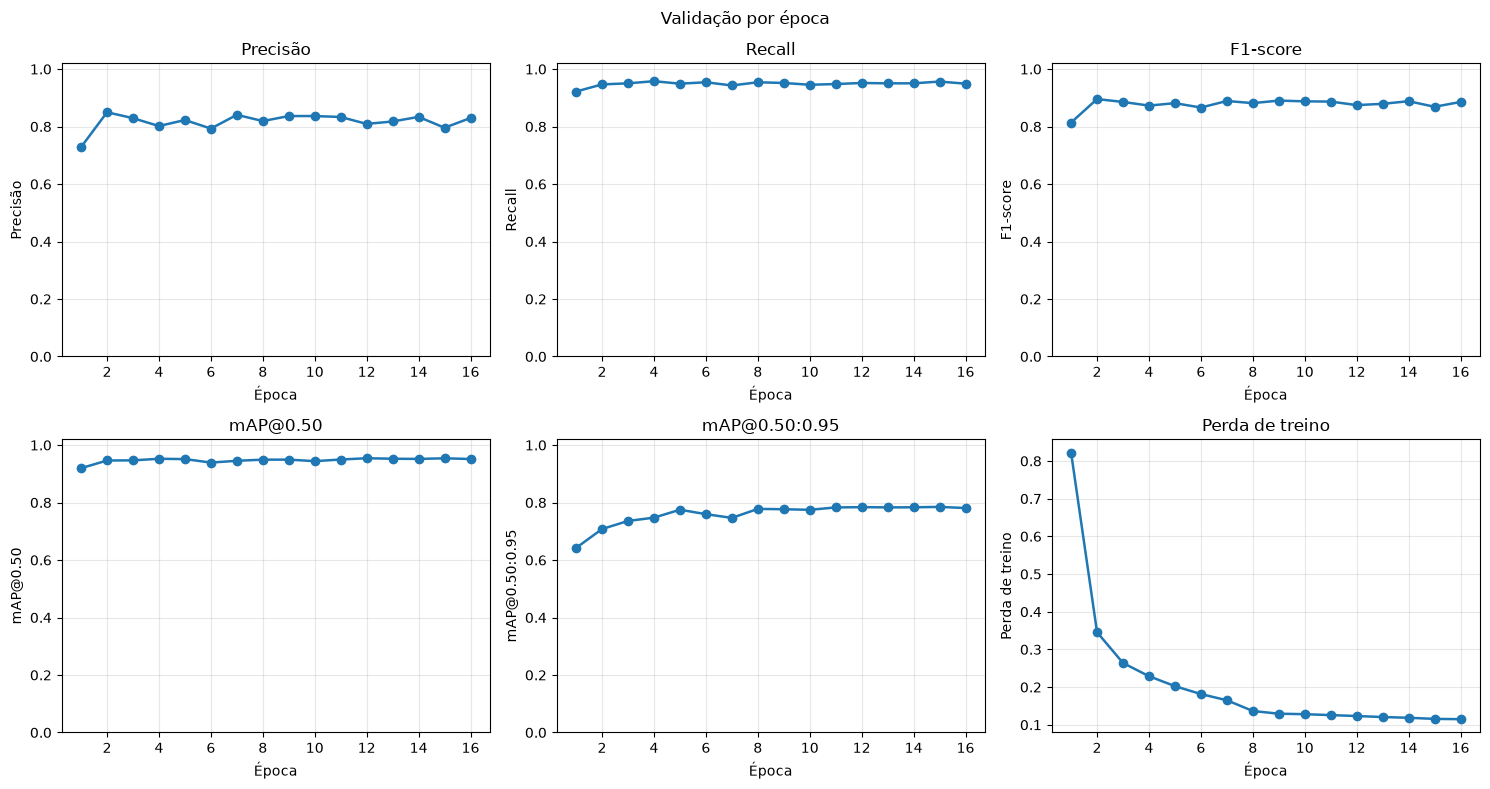

Época 16: perda=0.1149 | precisão=0.830 | recall=0.949 | F1=0.886 | mAP=0.781


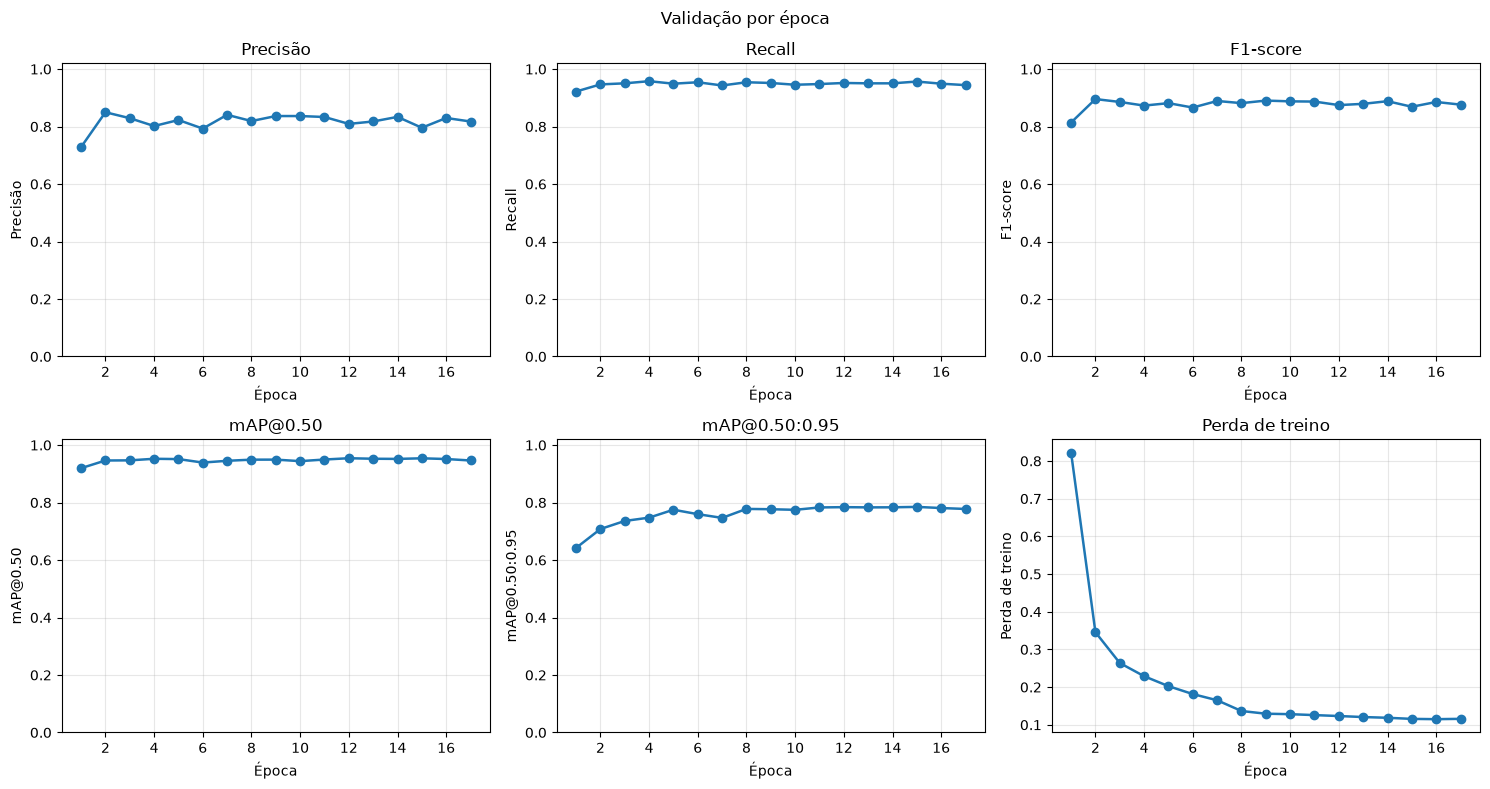

Época 17: perda=0.1158 | precisão=0.818 | recall=0.944 | F1=0.876 | mAP=0.778


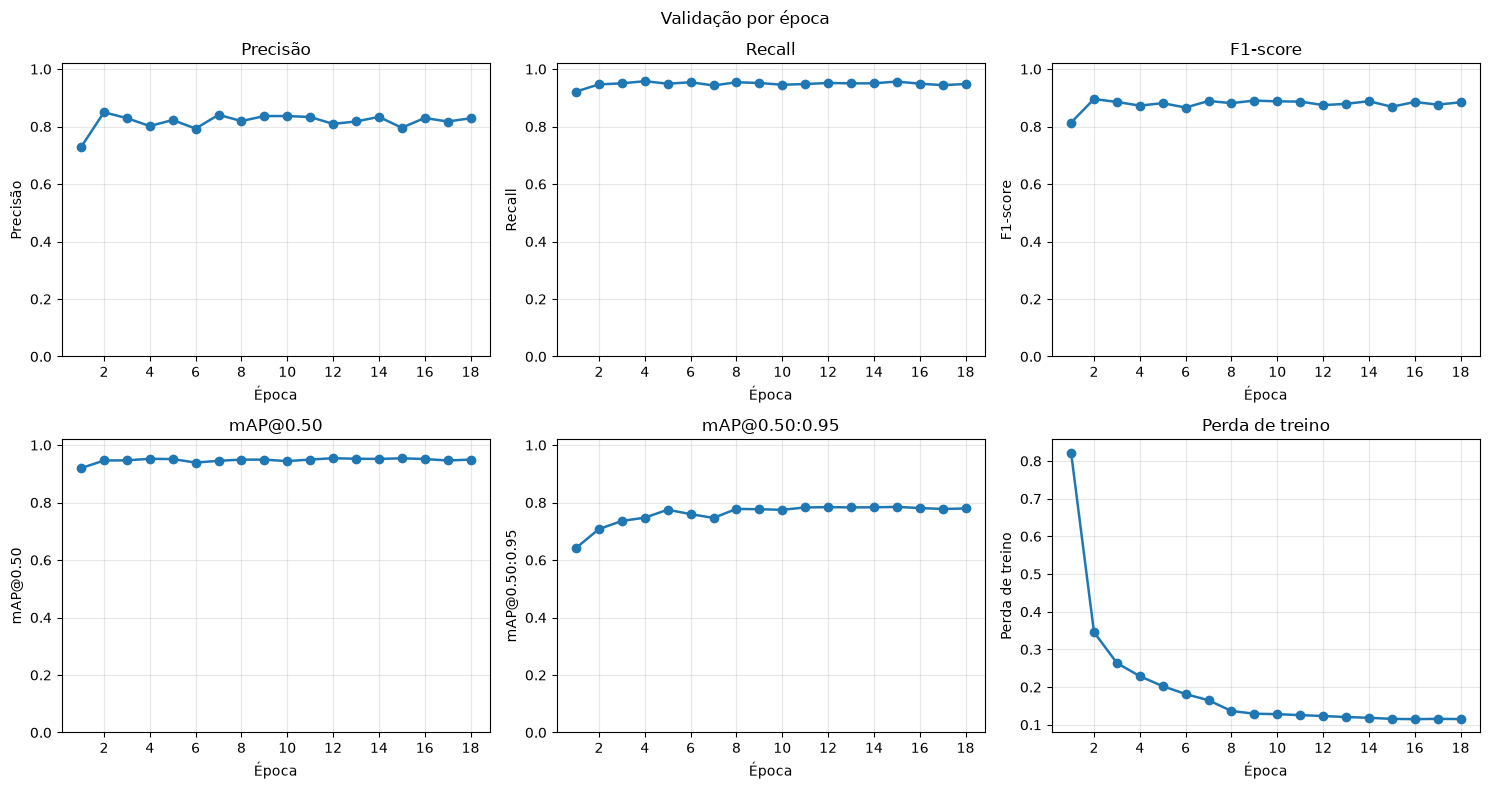

Época 18: perda=0.1152 | precisão=0.829 | recall=0.948 | F1=0.884 | mAP=0.779


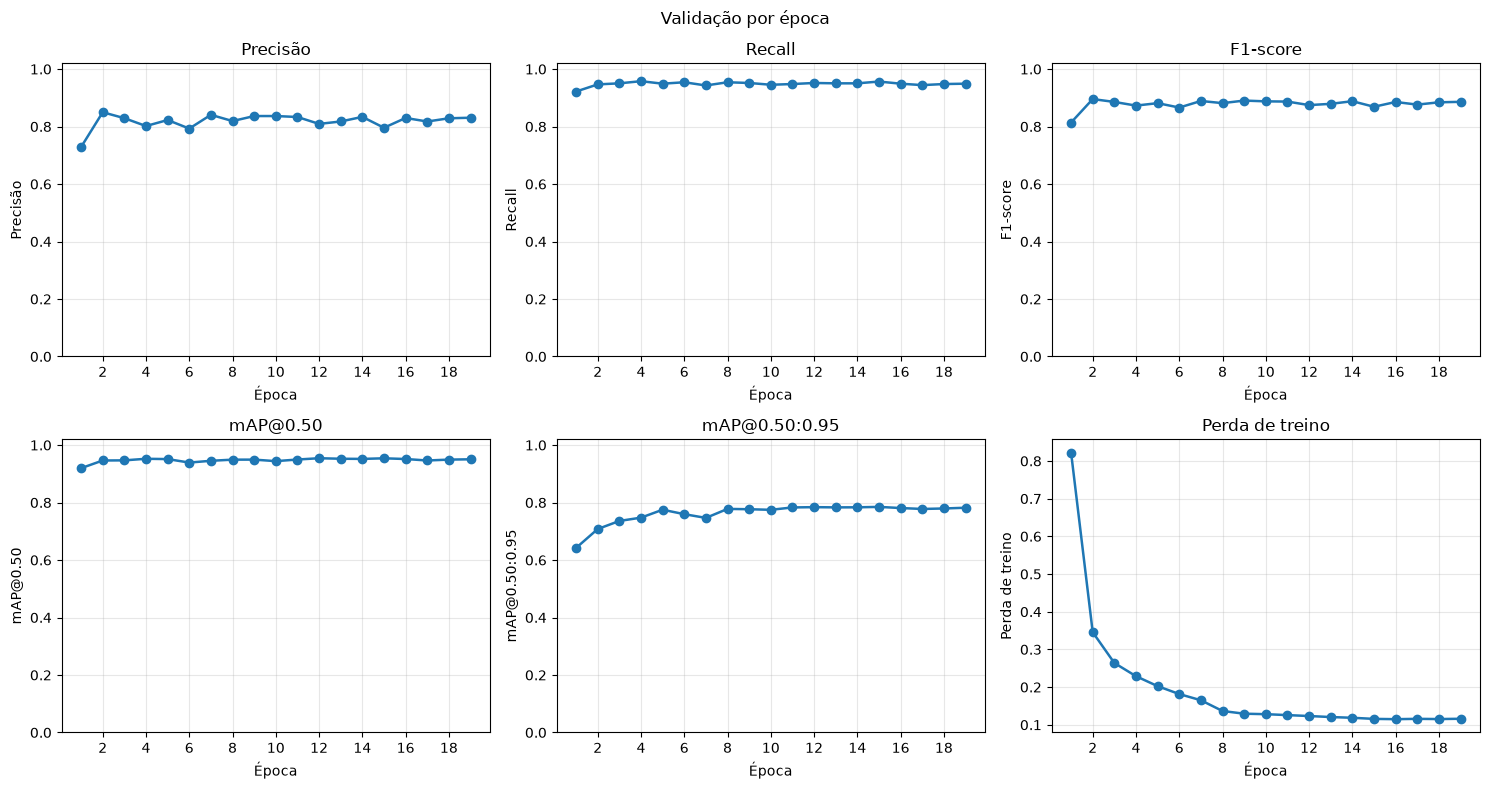

Época 19: perda=0.1160 | precisão=0.831 | recall=0.949 | F1=0.886 | mAP=0.782


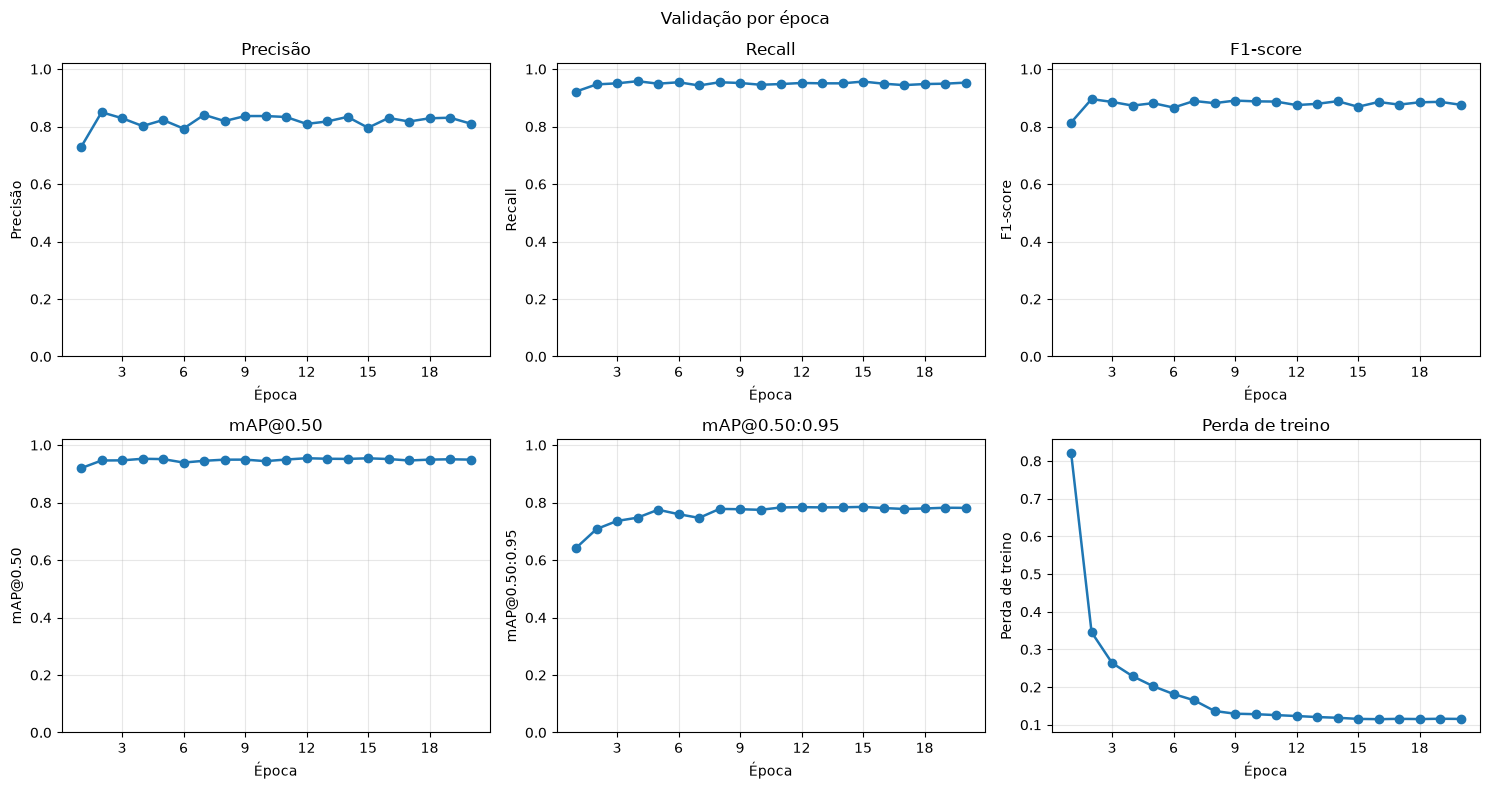

Época 20: perda=0.1156 | precisão=0.810 | recall=0.953 | F1=0.876 | mAP=0.782
Early stopping


In [12]:
if CONFIG['run_training'] or CONFIG['evaluate_test']:
    run_dir = create_run(CONFIG)
    print('Rodada:', run_dir)
    checkpoint = train_experiment(CONFIG, run_dir) if CONFIG['run_training'] else CONFIG['checkpoint_path']

    if CONFIG['evaluate_test']:
        if not checkpoint:
            raise ValueError('Informe checkpoint_path para avaliar um modelo existente')
        test_metrics = evaluate_checkpoint(checkpoint, run_dir, CONFIG)
        print(f'Teste — precisão={test_metrics["precision"]:.3f} | recall={test_metrics["recall"]:.3f} | '
              f'F1={test_metrics["f1"]:.3f} | mAP@0.50={test_metrics["map_50"]:.3f} | '
              f'mAP@0.50:0.95={test_metrics["map_50_95"]:.3f}')
else:
    print('Treinamento e avaliação desativados. Ajuste CONFIG para iniciar uma rodada.')